# Tax-loss harvesting: what it does, what it costs, what it cannot do, tested on 33 years of real S&P 500 data

*Not tax advice. The tax model is simplified; the reading guide at the end lists what it leaves out. The notebook runs offline in about two minutes and writes no files.*

**About the data.** Sections 2 to 5 and 7 run on the point-in-time S&P 500 panel, 1990 to 2022: real daily prices and real per-stock cash dividends for the 1,248 companies that were in the index at some date in those years, 631 of which were later delisted, with the membership as it stood on each date. The panel is an unlicensed mixed-source dataset (CRSP-derived data to 2006, then Yahoo, Tiingo and Quandl WIKI), downloaded with `make data-panel` for local use only. It is not redistributed with the repository, the files are git-ignored, and results that embed them should not be shared. If the files are missing the notebook cannot run. Sections 1, 5.1 and 6 are small hand-built illustrations of the mechanics and carry no conclusion about returns.

**Tax assumptions.** A taxable account for an Alberta resident with \$90,000 of other income. The model has 2025 tax tables only, and they are applied to every year from 1990 to 2022. The panel is in US dollars with no currency series, so gains are taxed in US dollars and the Canadian-dollar effect is ignored.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab, Config, Market, ScreenBuilder, ExitPolicy, ExitScreen
from screenlab.backtest import run
from screenlab.data import add_ratios
from screenlab.harvesting import TaxLossHarvest
from screenlab.taxes import CanadianTax, PlaceholderCanadianTax, TaxConfig, assess
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style
from screenlab.research import tax_plots as tp

BLUE, ORANGE, GREEN, GREY, RED, PURPLE = "#0072B2", "#E69F00", "#009E73", "#6B6B6B", "#D55E00", "#CC79A7"
HELD_COL = {"A": BLUE, "B": ORANGE, "C": GREEN, "cash": "#c9c8c2"}
OFF_COL, ON_COL = BLUE, RED                       # harvesting off / on, in every chart of section 2 and 3
BH_INDEX = "Buy and hold the index (after tax)"
plt.rcParams["figure.dpi"] = 80
_style()
usd = lambda v: f"-${-v:,.0f}" if round(v) < 0 else f"${v:,.0f}"
pc = lambda v, d=2: f"{100 * v:.{d}f}%"
pts = lambda v, d=2: f"{100 * v:+.{d}f}"
md = lambda text: display(Markdown(text.replace("$", r"\$")))      # a bare $ pair would be read as maths
mdates_num = mdates.date2num

# ---- tiny hand-built markets (the same builders as tests/test_harvesting.py) ---------------------------------------
CAP = 100_000.0
FLAT_TAX = PlaceholderCanadianTax(marginal_rate=0.40, federal_dtc=0.15, provincial_dtc=0.10, provincial_dtc_noneligible=0.03)
DATES = pd.bdate_range("2020-01-01", "2022-12-31")
END = DATES[-1]

def step(*pairs):
    "A price path that is 1.0 until the first date, then jumps to each level from its date on."
    s = pd.Series(1.0, index=DATES)
    for d, v in pairs:
        s[s.index >= d] = v
    return s

def toy_market(prices, caps):
    "`caps` {rebalance date: {name: market cap}} decides which names the 'top n by market cap' screen wants."
    rows = [dict(date=pd.Timestamp(d), ticker=t, sector="x", price=10.0, market_cap=c, dividend=0.0)
            for d, cs in caps.items() for t, c in cs.items()]
    return Market(add_ratios(pd.DataFrame(rows)), pd.DataFrame(prices))

def toy_screen(n):
    return ScreenBuilder("top", n=n).rank(market_cap="desc").build()

def toy_run(mkt, n, harvest, start="2020-01-01", exit=None, **cfg):
    tax = TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False, harvest=harvest)
    c = Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tax, exit=exit, **cfg)
    return run(toy_screen(n), mkt, c, start=start)

def held_segments(res, name, end=END, reentry=None, start=pd.Timestamp("2020-01-01")):
    "[(what is held, from, to)] around the first loss sale of `name`; cash until `reentry` (default: the sale day)."
    h = res.harvest.iloc[0]
    sale = h["date"]
    back = h["rebought"] if pd.notna(h["rebought"]) else end
    reentry = sale if reentry is None else reentry
    seg = [(name, start, sale)]
    if isinstance(h["replacement_name"], str):                 # a second pick: cash until re-entry, then the pick
        seg += [("cash", sale, reentry), (h["replacement_name"], reentry, back)]
    else:                                                       # no pick: cash until the name is bought again
        seg.append(("cash", sale, back))
    seg.append((name, back, end))
    return [s for s in seg if s[2] > s[1]]

def draw_held(ax, segs, label, window=None, denied_at=None):
    "One horizontal strip: what the account holds, when."
    for what, a, b in segs:
        ax.barh(0, (b - a).days, left=mdates_num(a), height=0.62, color=HELD_COL[what], edgecolor=SURFACE, lw=1.5)
        if (b - a).days > 45:
            ax.text(mdates_num(a) + (b - a).days / 2, 0, what, ha="center", va="center",
                    fontsize=9.5, color=INK if what in ("cash", "B") else "white", fontweight="bold")
    if window:
        ax.axvspan(mdates_num(window[0]), mdates_num(window[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
    if denied_at is not None:
        ax.plot([mdates_num(denied_at)], [0.5], marker="X", ms=11, color=RED, mec=SURFACE, clip_on=False, zorder=5)
    ax.set_yticks([]); ax.set_ylim(-0.5, 0.65); ax.grid(False)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10, color=INK)
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)

def strip_legend(fig, sale_label, sale_marker, sale_color, extra=()):
    "One legend under a figure of strips: what each colour of the strips is, the 30-day window, the sale and the denied loss."
    handles = [Patch(color=HELD_COL["A"], label="holds A"), Patch(color=HELD_COL["B"], label="holds B (the second pick)"),
               Patch(color=HELD_COL["cash"], label="holds cash"),
               Patch(color=ORANGE, alpha=0.20, label="30 days after the sale: buying A here denies the loss"),
               Line2D([], [], marker=sale_marker, color=sale_color, lw=0, ms=8, label=sale_label),
               Line2D([], [], marker="X", color=RED, lw=0, ms=9, label="loss denied by the rebuy"), *extra]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False)

# ---- section 1: one name, one loss -----------------------------------------------------------------------------------
A = step(("2020-07-01", 0.8))            # A falls 20% on 1 July 2020 and stays there
FLAT = step()                            # B and C do not move
caps = {d: dict(A=3, B=2, C=1) for d in ("2020-01-01", "2021-01-01", "2022-01-03")}   # the screen always wants A
mk1 = toy_market(dict(A=A, B=FLAT, C=FLAT), caps)

VARIANTS = {"Second pick": TaxLossHarvest(replacement="second_pick"),
            "Stay out": TaxLossHarvest(replacement="stay_out"),
            "Allow denial": TaxLossHarvest(on_repick="allow_denial")}
VAR_COL = {"Second pick": PURPLE, "Stay out": GREEN, "Allow denial": RED}
none1 = toy_run(mk1, 1, None)                         # buy and hold A: the screen holds A every year, nothing is ever sold
res1 = {k: toy_run(mk1, 1, h) for k, h in VARIANTS.items()}
SALE1 = res1["Second pick"].harvest.iloc[0]["date"]
BH_A = "Buy and hold A (never sell)"

rows = {BH_A: dict(sold="never", back="-", meanwhile="-", value=none1.curve.iloc[-1] * CAP, realized=0.0, denied=0.0, acb=CAP)}
for k, r in res1.items():
    h = r.harvest.iloc[0]
    segs = held_segments(r, "A")
    rows[k] = dict(sold=h["date"].date(), back=h["rebought"].date(),
                   meanwhile=" then ".join(w for w, a, b in segs[1:-1] if w != "cash") or "cash",
                   value=r.curve.iloc[-1] * CAP, realized=abs(r.tax.loc[2020, "realized_losses"]), denied=h["denied"] * CAP,
                   acb=r.curve.loc[h["rebought"]] * CAP + h["acb_added"] * CAP)
t1 = pd.DataFrame(rows).T[["sold", "back", "meanwhile", "value", "realized", "denied", "acb"]].fillna("-")
t1.columns = ["A sold on", "A held again on", "held meanwhile", "account value at the end of 2022", "loss realized in 2020", "loss denied",
              "ACB of A afterwards"]
for c in ("account value at the end of 2022", "loss realized in 2020", "loss denied", "ACB of A afterwards"):
    t1[c] = t1[c].map(usd)
FLAT_RATE = 0.20
LOSS1 = float(rows["Second pick"]["realized"])
days_out1 = {k: (res1[k].harvest.iloc[0]["rebought"] - SALE1).days for k in res1}
same_value1 = all(np.allclose(r.curve.to_numpy(), none1.curve.to_numpy()) for r in res1.values())


ud = lambda v, up="raised", down="lowered": up if v > 0 else down
saved_txt = lambda v: f"saved {usd(v)}" if v > 0 else f"cost {usd(-v)} more"

# ---- the real data: the point-in-time S&P 500 panel, 1990-2022 (local use only) --------------------------------------
lab = Lab.real_sp500(start="1990-01-01", end="2022-12-30")          # exactly these arguments, so the cached frames are read
CARD = lab.data_card().line()
TAXC = dict(model=CanadianTax("AB", other_income=90_000), capital=100_000, account="taxable")
H_ON = TaxLossHarvest(threshold_pct=0.10, when="year_end", replacement="second_pick", on_repick="avoid")
SCREENS = ["dogs", "momentum_12m", "stable_high_yield"]
SHORT = {"dogs": "dogs", "momentum_12m": "momentum_12m", "stable_high_yield": "stable_high_yield"}
SCREEN = "dogs"
runs = {}
for s_ in SCREENS:
    runs[s_] = (lab.backtest([s_], rebalance_months=12, tax=TaxConfig(**TAXC)),
                lab.backtest([s_], rebalance_months=12, tax=TaxConfig(harvest=H_ON, **TAXC)))

rep_off, rep_on = runs[SCREEN]
off, on = rep_off.results[SCREEN], rep_on.results[SCREEN]
idx = tp.index_result(rep_on)                         # buy and hold the passive index in the same account, taxed the same way
BL = rep_on.benchmark_label                           # SP500_TR, the real total return of the S&P 500
YEARS = (off.curve.index[-1] - off.curve.index[0]).days / 365.25
DAYS = (off.curve.index[-1] - off.curve.index[0]).days
tax_idx = idx.tax["cum_tax_paid"].iloc[-1]
at_idx = idx.after_tax_curve.iloc[-1] * CAP
idx_pre_cagr, idx_at_cagr = rep_on.table.loc[BL, "CAGR"], rep_on.table.loc[BL, "AfterTaxCAGR"]
idx_drag = rep_on.table.loc[BL, "TaxDrag/yr"]

def acct(res):
    "`Result.harvest` with loss and denied rescaled from pre-tax wealth units to the account's own dollars: the tax ledger is in the\n    account after tax was paid out of it, so each record is multiplied by after-tax wealth / pre-tax wealth on its sale date."
    ratio = res.after_tax_curve / res.curve
    sc = pd.to_datetime(res.harvest["date"]).map(ratio.asof).fillna(1.0).to_numpy()
    return res.harvest.assign(loss=res.harvest["loss"] * sc, denied=res.harvest["denied"] * sc)

def screen_stats(s):
    "Everything the summary and the tables say about one screen, harvesting off against on."
    ro_, rn_ = runs[s]
    o_, n_ = ro_.results[s], rn_.results[s]
    tb = lambda rep, c: rep.table.loc[s, c]
    hv_ = acct(n_)
    hs_ = hv_[hv_["source"] == "harvest"]
    back_ = hs_[hs_["rebought"].notna()]              # harvest sales whose name was bought again (a name that was delisted never is)
    dn_ = hv_[hv_["denied"] > 0]
    st = dict(pre_off=tb(ro_, "CAGR"), pre_on=tb(rn_, "CAGR"), at_off=tb(ro_, "AfterTaxCAGR"), at_on=tb(rn_, "AfterTaxCAGR"),
              drag_off=tb(ro_, "TaxDrag/yr"), drag_on=tb(rn_, "TaxDrag/yr"),
              turn_off=o_.turnover.sum() / YEARS, turn_on=n_.turnover.sum() / YEARS,
              cost_off=o_.costs.sum() / YEARS, cost_on=n_.costs.sum() / YEARS,
              tax_off=o_.tax["cum_tax_paid"].iloc[-1], tax_on=n_.tax["cum_tax_paid"].iloc[-1],
              val_off=o_.after_tax_curve.iloc[-1] * CAP, val_on=n_.after_tax_curve.iloc[-1] * CAP,
              pre_val_off=o_.curve.iloc[-1] * CAP, pre_val_on=n_.curve.iloc[-1] * CAP,
              n_sales=len(hv_), n_h=len(hs_), n_screen=int((hv_["source"] == "screen").sum()), n_back=len(back_), n_denied=len(dn_),
              n_denied_h=int((hs_["denied"] > 0).sum()),
              name_days=int(back_["days_out"].sum()), loss_sold=hv_["loss"].sum() * CAP, loss_h=hs_["loss"].sum() * CAP,
              loss_denied=hv_["denied"].sum() * CAP, avg_n=float(tb(rn_, "AvgN")),
              refund_on=n_.tax["refund"].sum(), refund_off=o_.tax["refund"].sum(),
              ry_on=[int(y) for y in n_.tax.index[n_.tax["refund"] > 0]], ry_off=[int(y) for y in o_.tax.index[o_.tax["refund"] > 0]],
              carry_on=n_.tax["loss_carry_out"].iloc[-1], carry_off=o_.tax["loss_carry_out"].iloc[-1],
              harv_yr=tb(rn_, "Harvested/yr"), defer_yr=tb(rn_, "TaxDeferred/yr"))
    st["d_pre"], st["d_at"] = st["pre_on"] - st["pre_off"], st["at_on"] - st["at_off"]
    st["d_drag"] = st["drag_off"] - st["drag_on"]                  # the fall in tax drag, in points of growth a year
    st["saved"] = st["tax_off"] - st["tax_on"]
    st["gain_at"], st["gain_pre"] = st["val_on"] - st["val_off"], st["pre_val_on"] - st["pre_val_off"]
    st["gain_tax"] = st["gain_at"] - st["gain_pre"]
    st["share_out"] = st["name_days"] / (st["avg_n"] * DAYS)
    st["gap_off"], st["gap_on"] = at_idx - st["val_off"], at_idx - st["val_on"]
    return st

ST = {s_: screen_stats(s_) for s_ in SCREENS}
DG = ST[SCREEN]                                        # the dogs numbers
tab_cols = ["CAGR", "AfterTaxCAGR", "TaxDrag/yr"]
tab2 = pd.DataFrame({"Buy and hold the index": rep_on.table.loc[BL], "Harvesting off": rep_off.table.loc[SCREEN],
                     "Harvesting on": rep_on.table.loc[SCREEN]}).T.reindex(columns=tab_cols)
tab2["Traded a year"] = [np.nan, DG["turn_off"], DG["turn_on"]]
tab2["Trading cost a year"] = [np.nan, DG["cost_off"], DG["cost_on"]]
tab2["Tax paid over the run"] = [tax_idx, DG["tax_off"], DG["tax_on"]]
tab2["Value of $100,000 after tax"] = [at_idx, DG["val_off"], DG["val_on"]]
tab2["Harvested/yr"] = [np.nan, np.nan, DG["harv_yr"]]
tab2["TaxDeferred/yr"] = [np.nan, np.nan, DG["defer_yr"]]
FMT2 = {"CAGR": "{:.2%}", "AfterTaxCAGR": "{:.2%}", "TaxDrag/yr": "{:.2%}", "Traded a year": "{:.0%}", "Trading cost a year": "{:.2%}",
        "Tax paid over the run": usd, "Value of $100,000 after tax": usd, "Harvested/yr": "{:.2%}", "TaxDeferred/yr": "{:.2%}"}

# the dogs numbers under the names the plotting cells use
turn_off, turn_on, cost_off, cost_on = DG["turn_off"], DG["turn_on"], DG["cost_off"], DG["cost_on"]
tax_off, tax_on = DG["tax_off"], DG["tax_on"]
at_off, at_on, gain_at, gain_pre, gain_tax = DG["val_off"], DG["val_on"], DG["gain_at"], DG["gain_pre"], DG["gain_tax"]
d_pre, d_drag, d_at = DG["d_pre"], DG["d_drag"], DG["d_at"]
off_at_cagr, on_at_cagr = DG["at_off"], DG["at_on"]
gap_off, gap_on = DG["gap_off"], DG["gap_on"]
hv = acct(on)
hsales = hv[hv["source"] == "harvest"]
n_h, n_sales, n_denied = DG["n_h"], DG["n_sales"], DG["n_denied"]
loss_sold, loss_denied = DG["loss_sold"], DG["loss_denied"]
refund_on, refund_off, refund_years_on, refund_years_off = DG["refund_on"], DG["refund_off"], DG["ry_on"], DG["ry_off"]

n_lower, n_years = int((on.tax["tax_paid"] < off.tax["tax_paid"]).sum()), len(on.tax)
tax_diff = off.tax["tax_paid"] - on.tax["tax_paid"]           # positive: harvesting on paid less that year
n_less, n_more = int((tax_diff > 0).sum()), int((tax_diff < 0).sum())
y_best, y_worst = int(tax_diff.idxmax()), int(tax_diff.idxmin())

# per year: losses sold by the harvest stage, losses the rule denied, sales at the screen's own rebalance
hv_y = hv.assign(year=pd.to_datetime(hv["date"]).dt.year)
yr_idx = list(on.tax.index)
loss_by_year = pd.DataFrame({
    "allowed": hv_y.groupby("year").apply(lambda g: (g["loss"] - g["denied"]).sum() * CAP),
    "denied": hv_y.groupby("year")["denied"].sum() * CAP}).reindex(yr_idx).fillna(0.0)
n_by_year = hv_y.groupby(["year", "source"]).size().unstack(fill_value=0).reindex(yr_idx).fillna(0)

# ---- the nine settings, daily bars (a month-end grid would be faster but would change the sale dates) --------------------
WHEN = ["year_end", "rebalance", "both"]; THR = [0.05, 0.10, 0.20]
curves, srows = {}, []
for when in WHEN:
    for th in THR:
        h_ = TaxLossHarvest(threshold_pct=th, when=when, replacement="second_pick", on_repick="avoid", report_deferral=False)
        r = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(harvest=h_, **TAXC)).results[SCREEN]
        curves[when, th] = (r.after_tax_curve - off.after_tax_curve) * CAP
        srows.append(dict(when=when, threshold=th, final=r.after_tax_curve.iloc[-1] * CAP,
                          gain=(r.after_tax_curve.iloc[-1] - off.after_tax_curve.iloc[-1]) * CAP,
                          tax_saved=off.tax["cum_tax_paid"].iloc[-1] - r.tax["cum_tax_paid"].iloc[-1],
                          harvests=int((r.harvest["source"] == "harvest").sum()) if r.harvest is not None else 0))
sens = pd.DataFrame(srows)
idx_gain_vs_off = at_idx - at_off
n_pos, n_neg = int((sens["gain"] > 0).sum()), int((sens["gain"] < 0).sum())
best, worst = sens.loc[sens["gain"].idxmax()], sens.loc[sens["gain"].idxmin()]
n_nonmono = sum(not (min(sens[(sens.when == w_) & (sens.threshold == t_)].gain.iloc[0] for t_ in (0.05, 0.20)) <= sens[(sens.when == w_) & (sens.threshold == 0.10)].gain.iloc[0] <= max(sens[(sens.when == w_) & (sens.threshold == t_)].gain.iloc[0] for t_ in (0.05, 0.20))) for w_ in WHEN)
WHEN_NAME = {"year_end": "at the year end only", "rebalance": "at the screen's rebalance only", "both": "at both"}
hv_by_thr = sens.groupby("threshold")["harvests"].agg(["min", "max"])

# ---- the crash years -------------------------------------------------------------------------------------------------
CRASH = {"2000-02": (2000, 2002), "2008-09": (2008, 2009)}
def crash_row(res_off, res_on, y0, y1):
    ys = list(range(y0, y1 + 1))
    hv_ = acct(res_on)
    yy = pd.to_datetime(hv_["date"]).dt.year
    inw = hv_[(yy >= y0) & (yy <= y1)]
    by = {y: res_on.tax.attrs["year_tax"][y].breakdown.get("refund_by_year", {}) for y in ys}
    back_years = sorted({int(k) for v in by.values() for k in v})
    t_on, t_off = res_on.tax, res_off.tax
    after5 = min(y1 + 5, int(t_on.index[-1]))
    return dict(harvest_loss=inw.loc[inw["source"] == "harvest", "loss"].sum() * CAP,
                screen_loss=inw.loc[inw["source"] == "screen", "loss"].sum() * CAP,
                denied=inw["denied"].sum() * CAP,
                real_on=-t_on.loc[ys, "realized_losses"].sum(), real_off=-t_off.loc[ys, "realized_losses"].sum(),
                gains_on=t_on.loc[ys, "realized_gains"].sum(), gains_off=t_off.loc[ys, "realized_gains"].sum(),
                refund_on=t_on.loc[ys, "refund"].sum(), refund_off=t_off.loc[ys, "refund"].sum(),
                back_years=back_years, carry_on=t_on.loc[y1, "loss_carry_out"], carry_off=t_off.loc[y1, "loss_carry_out"],
                carry5_on=t_on.loc[after5, "loss_carry_out"], carry5_off=t_off.loc[after5, "loss_carry_out"], after5=after5,
                gains_after=t_on.loc[y1 + 1:after5, "realized_gains"].sum(), losses_after=-t_on.loc[y1 + 1:after5, "realized_losses"].sum(),
                tax_off=t_off.loc[ys, "tax_paid"].sum(), tax_on=t_on.loc[ys, "tax_paid"].sum(),
                tax_idx=idx.tax.loc[ys, "tax_paid"].sum())
CR = {k: crash_row(off, on, *v) for k, v in CRASH.items()}


# ---- section 3: carry-back -------------------------------------------------------------------------------------------
def carry_events(years):
    ix = pd.date_range("2018-01-01", "2023-12-31", freq="D")
    ev = pd.DataFrame(0.0, index=ix, columns=["div_ca", "div_fx", "gain", "loss"])
    for y, (g, l) in years.items():
        ev.loc[f"{y}-06-01", ["gain", "loss"]] = [g, l]
    return pd.Series(1.0, index=ix), ev

def carry_case(years):
    curve, ev = carry_events(years)
    t, _ = assess(curve, ev, TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False), CAP)
    return t

# gains are in units of the $100,000 start: 0.20 = $20,000
case1 = carry_case({2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -0.65)})
case2 = carry_case({2018: (0.10, 0), 2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -1.20)})

# ---- section 4: exits ------------------------------------------------------------------------------------------------
class Flag:
    "A risk flag set by hand: on for the calendar days from `start` to `end`."
    name = "flag"
    def __init__(self, start, end):
        self.start, self.end = pd.Timestamp(start), pd.Timestamp(end)
    def compute(self, mkt, macro=None):
        return pd.Series(((mkt.index >= self.start) & (mkt.index <= self.end)).astype(float), index=mkt.index)

S = pd.Timestamp("2020-09-01")
a_exit = step(("2020-07-01", 0.8), ("2020-09-20", 1.0), ("2020-10-05", 1.1))
mk4 = toy_market(dict(A=a_exit, B=FLAT, C=FLAT), caps)

def exit_run(back_on, harvest):
    pol = ExitPolicy(ExitScreen([Flag(S, back_on - pd.Timedelta(days=1))], threshold=0.5, lag=0), switch_cost_bps=0.0)
    return toy_run(mk4, 1, harvest, exit=pol)

EXITS = {"Back in at S+10, second pick": (S + pd.Timedelta(days=10), TaxLossHarvest(replacement="second_pick")),
         "Back in at S+31, second pick": (S + pd.Timedelta(days=31), TaxLossHarvest(replacement="second_pick")),
         "Back in at S+10, allow denial": (S + pd.Timedelta(days=10), TaxLossHarvest(on_repick="allow_denial"))}
EXIT_COL = dict(zip(EXITS, (PURPLE, GREEN, RED)))
res4 = {k: exit_run(b, h) for k, (b, h) in EXITS.items()}
BH_A4 = "Buy and hold A (no exit, never sell)"
CHK = pd.Timestamp("2020-10-06")
rows_4 = [{"variant": BH_A4, "sale recorded as": "-", "bought instead": "-", "A held again on": "-", "loss": "$0", "denied": "$0",
         "wealth on 6 Oct": usd(a_exit.loc[CHK] * CAP), "loss realized in 2020": "$0"}]
for k, r in res4.items():
    h = r.harvest.iloc[0]
    rows_4.append({"variant": k, "sale recorded as": h["source"], "loss": usd(h["loss"] * CAP),
                 "bought instead": h["replacement_name"] if isinstance(h["replacement_name"], str) else "A (the same name)",
                 "A held again on": h["rebought"].date(), "denied": usd(h["denied"] * CAP),
                 "wealth on 6 Oct": usd(r.curve.loc[CHK] * CAP), "loss realized in 2020": usd(abs(r.tax.loc[2020, "realized_losses"]))})
t4 = pd.DataFrame(rows_4).set_index("variant")[["sale recorded as", "loss", "bought instead", "A held again on", "denied", "loss realized in 2020", "wealth on 6 Oct"]]
w4 = {k: r.curve.loc[CHK] * CAP for k, r in res4.items()}
bh4 = a_exit.loc[CHK] * CAP


# ---- the summary at the top ------------------------------------------------------------------------------------------
dg, mo, sh = ST["dogs"], ST["momentum_12m"], ST["stable_high_yield"]
n_up = sum(ST[s_]["d_at"] > 0 for s_ in SCREENS)
n_beat = sum(ST[s_]["val_on"] > at_idx for s_ in SCREENS)
den_h = sum(ST[s_]["n_denied_h"] for s_ in SCREENS)
n_names = int(CARD.split(", ")[2].split()[0]); n_del = int(CARD.split("delisted yes (")[1].split(")")[0])
md(f"""## Summary

**What harvesting cost.** The test was $100,000 in a taxable Alberta account from 1990 to 2022 on the real point-in-time S&P 500 ({n_names:,} names, {n_del} of them delisted), three screens rebalanced yearly, with harvesting set to sell any name down more than 10% at the year end and to hold the second pick for 30 days. Harvesting made every screen trade more. Dogs went from {pc(dg["turn_off"], 0)} of its value a year to {pc(dg["turn_on"], 0)}, momentum_12m from {pc(mo["turn_off"], 0)} to {pc(mo["turn_on"], 0)} and stable_high_yield from {pc(sh["turn_off"], 0)} to {pc(sh["turn_on"], 0)}, and trading cost rose from {pc(dg["cost_off"])} to {pc(dg["cost_on"])} of the portfolio a year on dogs, from {pc(mo["cost_off"])} to {pc(mo["cost_on"])} on momentum_12m and from {pc(sh["cost_off"])} to {pc(sh["cost_on"])} on stable_high_yield. The stage made {dg["n_h"]}, {mo["n_h"]} and {sh["n_h"]} year-end sales, and the accounts spent {dg["name_days"]:,}, {mo["name_days"]:,} and {sh["name_days"]:,} name-days out of the names the screens had chosen ({pc(dg["share_out"], 1)}, {pc(mo["share_out"], 1)} and {pc(sh["share_out"], 1)} of all their name-time). The superficial-loss rule denied part of the loss on {dg["n_denied"]} of {dg["n_sales"]} loss sales on dogs ({usd(dg["loss_denied"])} of {usd(dg["loss_sold"])} sold, in the account's own dollars), {mo["n_denied"]} of {mo["n_sales"]} on momentum_12m and {sh["n_denied"]} of {sh["n_sales"]} on stable_high_yield, and {den_h} of those denied sales were ones the harvest stage chose.

**What it was worth.** Tax paid over the run changed from {usd(dg["tax_off"])} to {usd(dg["tax_on"])} on dogs, which {saved_txt(dg["saved"])}, from {usd(mo["tax_off"])} to {usd(mo["tax_on"])} on momentum_12m, which {saved_txt(mo["saved"])}, and from {usd(sh["tax_off"])} to {usd(sh["tax_on"])} on stable_high_yield, which {saved_txt(sh["saved"])}. In after-tax growth a year, harvesting changed dogs by {pts(dg["d_at"])} points ({pts(dg["d_drag"])} from lower tax drag and {pts(dg["d_pre"])} from the before-tax return), momentum_12m by {pts(mo["d_at"])} ({pts(mo["d_drag"])} and {pts(mo["d_pre"])}) and stable_high_yield by {pts(sh["d_at"])} ({pts(sh["d_drag"])} and {pts(sh["d_pre"])}), so it raised after-tax growth on {n_up} of 3 screens. The before-tax part is how the second picks, the 30 days away from the sold names and the extra trading compare with holding on, and one history cannot say whether it is luck or a lasting cost. Carry-back refunds were {usd(dg["refund_on"])} with harvesting against {usd(dg["refund_off"])} without on dogs, {usd(mo["refund_on"])} against {usd(mo["refund_off"])} on momentum_12m and {usd(sh["refund_on"])} against {usd(sh["refund_off"])} on stable_high_yield. Buying and holding the index (SP500_TR) turned $100,000 into {usd(at_idx)} after tax, {pc(idx_at_cagr)} a year with {usd(tax_idx)} of tax. Against it, dogs ended {usd(dg["gap_on"])} behind with harvesting and {usd(dg["gap_off"])} behind without, momentum_12m {usd(mo["gap_on"])} and {usd(mo["gap_off"])}, and stable_high_yield {usd(sh["gap_on"])} and {usd(sh["gap_off"])}; the harvesting portfolio beat the index after tax on {n_beat} of 3 screens.
""")


## Summary

**What harvesting cost.** The test was \$100,000 in a taxable Alberta account from 1990 to 2022 on the real point-in-time S&P 500 (1,248 names, 631 of them delisted), three screens rebalanced yearly, with harvesting set to sell any name down more than 10% at the year end and to hold the second pick for 30 days. Harvesting made every screen trade more. Dogs went from 76% of its value a year to 137%, momentum_12m from 93% to 144% and stable_high_yield from 50% to 76%, and trading cost rose from 0.38% to 0.69% of the portfolio a year on dogs, from 0.47% to 0.72% on momentum_12m and from 0.25% to 0.38% on stable_high_yield. The stage made 142, 125 and 51 year-end sales, and the accounts spent 4,142, 4,091 and 1,546 name-days out of the names the screens had chosen (3.6%, 3.5% and 1.3% of all their name-time). The superficial-loss rule denied part of the loss on 44 of 248 loss sales on dogs (\$142,497 of \$2,695,670 sold, in the account's own dollars), 32 of 261 on momentum_12m and 15 of 117 on stable_high_yield, and 0 of those denied sales were ones the harvest stage chose.

**What it was worth.** Tax paid over the run changed from \$765,975 to \$547,748 on dogs, which saved \$218,227, from \$220,226 to \$127,121 on momentum_12m, which saved \$93,105, and from \$295,693 to \$318,722 on stable_high_yield, which cost \$23,029 more. In after-tax growth a year, harvesting changed dogs by -0.96 points (+0.70 from lower tax drag and -1.66 from the before-tax return), momentum_12m by -1.36 (+0.25 and -1.61) and stable_high_yield by +0.35 (+0.07 and +0.28), so it raised after-tax growth on 1 of 3 screens. The before-tax part is how the second picks, the 30 days away from the sold names and the extra trading compare with holding on, and one history cannot say whether it is luck or a lasting cost. Carry-back refunds were \$21,999 with harvesting against \$50,142 without on dogs, \$35,277 against \$103,986 on momentum_12m and \$8,841 against \$34,059 on stable_high_yield. Buying and holding the index (SP500_TR) turned \$100,000 into \$1,706,756 after tax, 9.28% a year with \$108,392 of tax. Against it, dogs ended \$1,058,251 behind with harvesting and \$843,373 behind without, momentum_12m \$799,230 and \$349,973, and stable_high_yield \$607,902 and \$716,374; the harvesting portfolio beat the index after tax on 0 of 3 screens.


## How harvesting works

When a stock you own has fallen, selling it makes a **capital loss**. In a taxable account that loss cancels capital gains of this year, of the three years before, or of any later year, so it lowers your tax. **Harvesting** means selling a loser on purpose, near the end of the year, for that reason.

The Canadian **superficial-loss rule** limits it. If you, your spouse or a corporation you control buy the same stock within 30 days before or after the sale and still hold it at the end of that window, the loss is **denied**. A denied loss is not gone: it is added to the cost (the adjusted cost base, ACB) of the shares bought, so it comes back only when those shares are finally sold.

The library's harvesting stage sells losers, keeps the name on a **blocklist** for 30 days, and by default buys the screen's **second pick** meanwhile so the account stays invested. The notebook shows the rule first on one hand-built name, where the arithmetic can be checked by eye (section 1), and then measures the technique on real data: the dogs screen over 33 years (section 2), nine other settings of the stage (section 3), two more screens (section 4), and the two crashes inside the history (section 5, which opens with the carry-back arithmetic on hand-built numbers). Section 6 shows an exit signal forcing a loss sale on a hand-built name, and section 7 lists what is real, what is approximate and what the model leaves out. The real-data sections carry the conclusions. They use one history and no Monte Carlo, so they measure what harvesting would have done in the market that happened and not what it will do.

Every chart and table carries a grey dashed base case. On the real data it is buying and holding the real S&P 500 total return (SP500_TR) in the same account, taxed the same way, which is the choice an investor faces before deciding to run a screen at all. The comparison that isolates the tax technique is the same screen with harvesting off, and it appears next to the base case. On the one-name markets the base case is buying and holding the same name and never selling. Each section opens with the question it answers, shows the evidence, and closes under "What the evidence says".

## 1. One name, one loss (a hand-built illustration)

This section asks what the superficial-loss rule does to a single loss, and what the three ways of spending the 30 days afterwards are worth. It comes first because one name and one loss can be checked by eye, before section 2 adds a real screen with many names, gains and trading costs. The market here is made up and the section carries no conclusion about returns; it exists to show the mechanics.

Stocks A, B and C move in steps so that the sums are exact. The screen is "hold the single biggest company", which is A, every year. A fell 20% on 1 July 2020 and stayed there. The account started with \$100,000 on 1 January 2020, and capital gains tax is a flat 20% of the gain, so a \$20,000 loss is worth \$4,000 of tax.

The base case is buying A and holding it without ever selling. That is the right comparison here because it has exactly the same exposure to A as every variant and involves no tax-driven trade, so any difference between a variant and the base case is caused by harvesting alone.

With harvesting on (threshold 10%), the stage sold A on the last trading day of 2020 and booked the loss. The screen wanted A again on 1 January 2021, a day later, which is the purchase the rule punishes. The three variants differ in what happens next. Under **second pick**, the default, A is blocked for 30 days, B (the next company down the screen's list) is held instead, and A is swapped back after the window. Under **stay out**, the proceeds wait in cash until the screen next wants A after the window. Under **allow denial**, A is bought straight back and the loss is denied.

In [2]:
display(t1)
print(f"flat tax rate 20%: a realized loss of {usd(LOSS1)} is worth {usd(LOSS1 * FLAT_RATE)} of tax in 2020.")

,A sold on,A held again on,held meanwhile,account value at the end of 2022,loss realized in 2020,loss denied,ACB of A afterwards
Buy and hold A (never sell),never,-,-,"$80,000",$0,$0,"$100,000"
Second pick,2020-12-31,2021-02-01,B,"$80,000","$20,000",$0,"$80,000"
Stay out,2020-12-31,2022-01-03,cash,"$80,000","$20,000",$0,"$80,000"
Allow denial,2020-12-31,2021-01-01,cash,"$80,000",$0,"$20,000","$100,000"


flat tax rate 20%: a realized loss of $20,000 is worth $4,000 of tax in 2020.


In [3]:
md(f"""
Second pick and stay out realized the full {usd(LOSS1)} loss in 2020, and the shares of A held afterwards cost only {usd(rows['Second pick']['acb'])}, so the loss was used and not merely postponed. Allow denial realized nothing in 2020. Its {usd(rows['Allow denial']['denied'])} was parked in the cost base of the shares bought back, which stood at {usd(rows['Allow denial']['acb'])} for a position worth {usd(rows['Allow denial']['value'])}, and it comes back only when those shares are sold. Buy and hold realized nothing and held the same position at the same {usd(CAP)} cost. The account was worth {usd(rows['Second pick']['value'])} at the end of 2022 in all four rows, so no variant changed what the account was worth. Each changed what the tax system owed.
""")


Second pick and stay out realized the full \$20,000 loss in 2020, and the shares of A held afterwards cost only \$80,000, so the loss was used and not merely postponed. Allow denial realized nothing in 2020. Its \$20,000 was parked in the cost base of the shares bought back, which stood at \$100,000 for a position worth \$80,000, and it comes back only when those shares are sold. Buy and hold realized nothing and held the same position at the same \$100,000 cost. The account was worth \$80,000 at the end of 2022 in all four rows, so no variant changed what the account was worth. Each changed what the tax system owed.


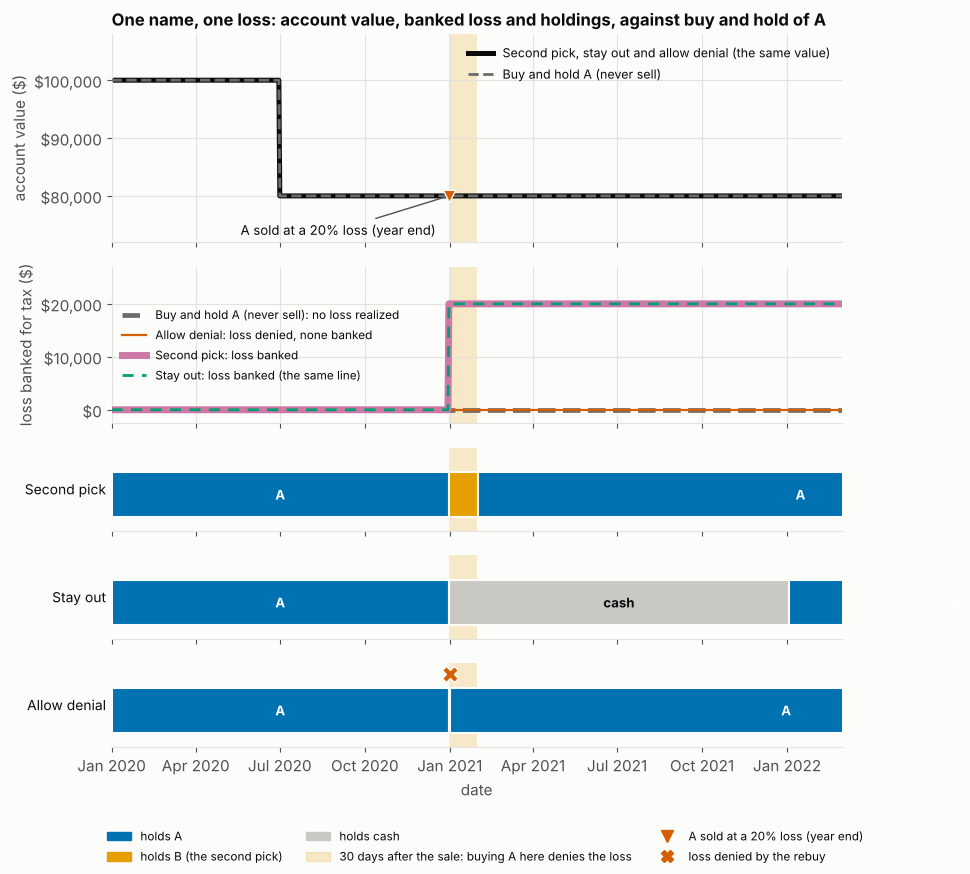

In [4]:
fig, axs = plt.subplots(5, 1, sharex=True, figsize=(10, 8.8), gridspec_kw=dict(height_ratios=[2.0, 1.5, 0.8, 0.8, 0.8], hspace=0.2))
win = (SALE1, SALE1 + pd.Timedelta(days=30))

def banked(r):
    "Realized losses waiting to be used against gains, from the tax table (known at each year end)."
    s = pd.Series(0.0, index=DATES)
    for y, v in r.tax["loss_carry_out"].items():
        s[s.index >= pd.Timestamp(f"{y}-12-31")] = max(float(v), 0.0)
    return s

ax = axs[0]
v = res1["Second pick"].curve * CAP
ax.plot(v.index, v.values, color=INK, lw=3.6, label="Second pick, stay out and allow denial (the same value)")
bh = none1.curve * CAP
ax.plot(bh.index, bh.values, color=tp.INDEX_COL, ls="--", lw=2.0, label=BH_A, zorder=4)
ax.scatter([SALE1], [v.loc[SALE1]], marker="v", s=80, color=RED, zorder=5, edgecolor=SURFACE)
ax.annotate("A sold at a 20% loss (year end)", (SALE1, v.loc[SALE1]), xytext=(-150, -28), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.set_ylim(72_000, 108_000); ax.set_ylabel("account value ($)")
ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="upper right", fontsize=9)
ax.set_title("One name, one loss: account value, banked loss and holdings, against buy and hold of A", loc="left", fontsize=12, fontweight="bold")

ax = axs[1]
ax.plot(DATES, banked(none1).values, color=tp.INDEX_COL, ls="--", lw=3.4, label=BH_A + ": no loss realized", zorder=2)
ax.plot(DATES, banked(res1["Allow denial"]).values, color=VAR_COL["Allow denial"], lw=1.6, label="Allow denial: loss denied, none banked", zorder=3)
ax.plot(DATES, banked(res1["Second pick"]).values, color=VAR_COL["Second pick"], lw=5.0, label="Second pick: loss banked", zorder=3)
ax.plot(DATES, banked(res1["Stay out"]).values, color=VAR_COL["Stay out"], lw=2.0, ls=(0, (4, 3)), label="Stay out: loss banked (the same line)", zorder=4)
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.set_ylim(-2_500, 27_000); ax.set_ylabel("loss banked for tax ($)")
ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="center left", fontsize=8.5)

for ax_, (name, r) in zip(axs[2:], res1.items()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A"), name, window=win, denied_at=h["rebought"] if h["denied"] > 0 else None)
for ax_ in axs[:2]:
    ax_.set_facecolor(SURFACE)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axs[-1].set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-03-01"))
axs[-1].set_xlabel("date")
strip_legend(fig, "A sold at a 20% loss (year end)", "v", RED)
fig.subplots_adjust(left=0.17, bottom=0.14, top=0.95)
plt.show()

In [5]:
md(f"""
**What the evidence says.** Harvesting did not change the account's value in this market, which was {usd(rows['Second pick']['value'])} at the end of 2022 with or without it ({'identical on every day' if same_value1 else 'different on some days'}). It changed the tax position. Second pick and stay out banked a {usd(LOSS1)} loss, worth {usd(LOSS1 * FLAT_RATE)} of tax at 20% once there are gains to set it against, and the account paid nothing for that because A and B did not move while the account was away from A. Allow denial gave the benefit back, which makes a rebuy inside the window the one move that cancels the saving. Second pick and stay out tie here only because nothing moved: second pick was out of A for {days_out1['Second pick']} days and stay out for {days_out1['Stay out']}. On a path where A recovers, those days cost money, and section 6 shows how much.
""")


**What the evidence says.** Harvesting did not change the account's value in this market, which was \$80,000 at the end of 2022 with or without it (identical on every day). It changed the tax position. Second pick and stay out banked a \$20,000 loss, worth \$4,000 of tax at 20% once there are gains to set it against, and the account paid nothing for that because A and B did not move while the account was away from A. Allow denial gave the benefit back, which makes a rebuy inside the window the one move that cancels the saving. Second pick and stay out tie here only because nothing moved: second pick was out of A for 32 days and stay out for 368. On a path where A recovers, those days cost money, and section 6 shows how much.


## 2. Dogs of the S&P 500, 1990 to 2022: harvesting on and off

Section 1 showed that one loss can be banked at no cost in wealth when nothing moves. This section asks what harvesting is worth on a real screen that holds ten names for 33 years, pays tax on gains and on dividends, trades at a cost, holds second picks while real prices move, and lives through the 2000-02 and 2008-09 crashes. It follows from section 1 because the mechanics are the same. What is new is that the second picks, the trading costs, the delistings and the gains the losses are set against are real quantities and not zero.

The screen is **dogs**: on each rebalance date it buys the ten highest trailing dividend yields of the whole S&P 500, equal weighted, and rebalances once a year. That is not the 30-largest-stock dogs of the Globe and Mail, because the panel has no market cap. A high trailing yield after a price collapse is real and is kept, so in 2008-09 the screen buys distressed financials, which is why its worst fall is deep (see the table). A name whose prices end takes the library's 30% delisting haircut. The account is taxable, in Alberta, with \$90,000 of other income. With harvesting on, the stage sold any loser down more than 10% at each year end and held the second pick for 30 days.

The base case is buying and holding the real S&P 500 total return (SP500_TR) in the same account, taxed the same way: dividends taxed as received, and gains taxed only if the index is sold. It is the grey dashed line in every chart and a row in every table. The comparison that isolates the tax technique is harvesting on against harvesting off, the same portfolio without the year-end sales, and both appear in every chart as well.

### 2.1 Growth and tax

The first question is whether harvesting raised after-tax growth, and by how much against both comparisons.

In [6]:
print(CARD)
print("harvesting:", H_ON.describe())
display(tab2.style.format(FMT2, na_rep="-"))
print(f"change in growth a year, in percentage points: before tax {pts(d_pre)}, less tax drag {pts(d_drag)}, after tax {pts(d_at)}")
print(f"tax paid over the run: {usd(tax_off)} off, {usd(tax_on)} on, {usd(tax_idx)} for buy and hold of the index;"
      f" after-tax value of $100,000: {usd(at_off)} off, {usd(at_on)} on, {usd(at_idx)} for buy and hold of the index")

Data: sp500_panel, 1990-01-02..2022-12-30, 1248 names, benchmark SP500_TR (total_return), PIT yes, delisted yes (631), survivorship -0.7%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
harvesting: on (threshold 10%, second pick, 30-day window)


,CAGR,AfterTaxCAGR,TaxDrag/yr,Traded a year,Trading cost a year,Tax paid over the run,"Value of $100,000 after tax",Harvested/yr,TaxDeferred/yr
Buy and hold the index,9.92%,9.28%,0.63%,-,-,"$108,392","$1,706,756",-,-
Harvesting off,11.34%,6.99%,4.35%,76%,0.38%,"$765,975","$863,382",-,-
Harvesting on,9.69%,6.04%,3.65%,137%,0.69%,"$547,748","$648,505",16.82%,6.84%


change in growth a year, in percentage points: before tax -1.66, less tax drag +0.70, after tax -0.96
tax paid over the run: $765,975 off, $547,748 on, $108,392 for buy and hold of the index; after-tax value of $100,000: $863,382 off, $648,505 on, $1,706,756 for buy and hold of the index


In [7]:
md(f"""
The table has one row for each portfolio. **Traded a year** is the one-way share of the portfolio sold and bought in a year, and **Trading cost a year** is what that cost. **Harvested/yr** is the average loss sold each year as a share of wealth. **TaxDeferred/yr** is the tax that loss postponed, found by re-running the same portfolio without harvesting. It is a deferral: a harvested loss lowers the cost of what is held afterwards, so the saving is partly a loan from the tax authority, repaid when the gain is realized. **TaxDeferred/yr should be ignored in a TFSA or RRSP**, where there is nothing to defer.

The before-tax return also changed, because for 30 days each year the account held different stocks. The line printed under the table splits the after-tax change of {pts(d_at)} points a year into that change in the before-tax return, {pts(d_pre)} points, which includes the extra trading cost of {pc(cost_on - cost_off)} a year, and the fall in tax drag, {pts(d_drag)} points, which is the harvest itself.
""")


The table has one row for each portfolio. **Traded a year** is the one-way share of the portfolio sold and bought in a year, and **Trading cost a year** is what that cost. **Harvested/yr** is the average loss sold each year as a share of wealth. **TaxDeferred/yr** is the tax that loss postponed, found by re-running the same portfolio without harvesting. It is a deferral: a harvested loss lowers the cost of what is held afterwards, so the saving is partly a loan from the tax authority, repaid when the gain is realized. **TaxDeferred/yr should be ignored in a TFSA or RRSP**, where there is nothing to defer.

The before-tax return also changed, because for 30 days each year the account held different stocks. The line printed under the table splits the after-tax change of -0.96 points a year into that change in the before-tax return, -1.66 points, which includes the extra trading cost of 0.31% a year, and the fall in tax drag, +0.70 points, which is the harvest itself.


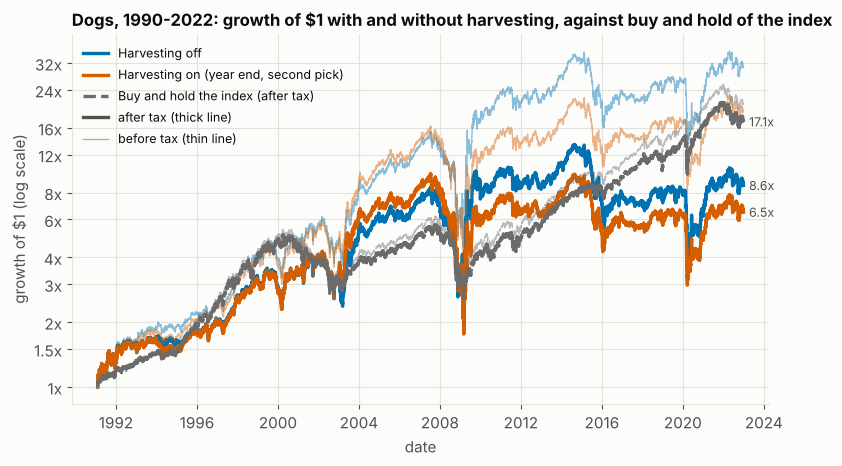

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tp.after_tax_curves({"Harvesting off": off, "Harvesting on (year end, second pick)": on}, baseline=idx, ax=ax,
                    title="Dogs, 1990-2022: growth of $1 with and without harvesting, against buy and hold of the index")
ax.set_ylabel("growth of $1 (log scale)"); ax.set_xlabel("date")
plt.show()

In [9]:
md(f"""
**What the evidence says.** Harvesting {ud(d_at)} after-tax growth on dogs from {pc(off_at_cagr)} to {pc(on_at_cagr)} a year, and the after-tax value of $100,000 went from {usd(at_off)} to {usd(at_on)}. The tax part of the change was {pts(d_drag)} points a year, as the tax drag went from {pc(DG["drag_off"])} to {pc(DG["drag_on"])}, and it was {ud(d_drag, "a gain", "a loss")}. The before-tax part was {pts(d_pre)} points, as before-tax growth went from {pc(DG["pre_off"])} to {pc(DG["pre_on"])} and $100,000 before tax became {usd(DG["pre_val_off"])} without harvesting and {usd(DG["pre_val_on"])} with it. About {100 * (cost_on - cost_off):.2f} points a year of that is extra trading cost. The remainder is what the account earned in the second picks and gave up in the sold names, which a single history cannot separate into luck and a lasting effect: a name sold at a year-end loss may rebound in January, and a second pick has no such tendency. Neither portfolio came near the base case. Buying and holding the index grew {pc(idx_at_cagr)} a year after tax and turned $100,000 into {usd(at_idx)}, {usd(gap_on)} more than the harvesting portfolio and {usd(gap_off)} more than the same screen without harvesting.
""")


**What the evidence says.** Harvesting lowered after-tax growth on dogs from 6.99% to 6.04% a year, and the after-tax value of \$100,000 went from \$863,382 to \$648,505. The tax part of the change was +0.70 points a year, as the tax drag went from 4.35% to 3.65%, and it was a gain. The before-tax part was -1.66 points, as before-tax growth went from 11.34% to 9.69% and \$100,000 before tax became \$3,079,959 without harvesting and \$1,909,423 with it. About 0.31 points a year of that is extra trading cost. The remainder is what the account earned in the second picks and gave up in the sold names, which a single history cannot separate into luck and a lasting effect: a name sold at a year-end loss may rebound in January, and a second pick has no such tendency. Neither portfolio came near the base case. Buying and holding the index grew 9.28% a year after tax and turned \$100,000 into \$1,706,756, \$1,058,251 more than the harvesting portfolio and \$843,373 more than the same screen without harvesting.


### 2.2 Where the tax went

The second question is how the tax changed, year by year. A harvested loss is set against gains in the year it is sold, carried back against tax already paid, or carried forward, so the saving can arrive in a different year from the sale. The charts below show the tax paid each year, the stock of unused losses carried forward, and the timeline of the sales, each against buy and hold of the index.

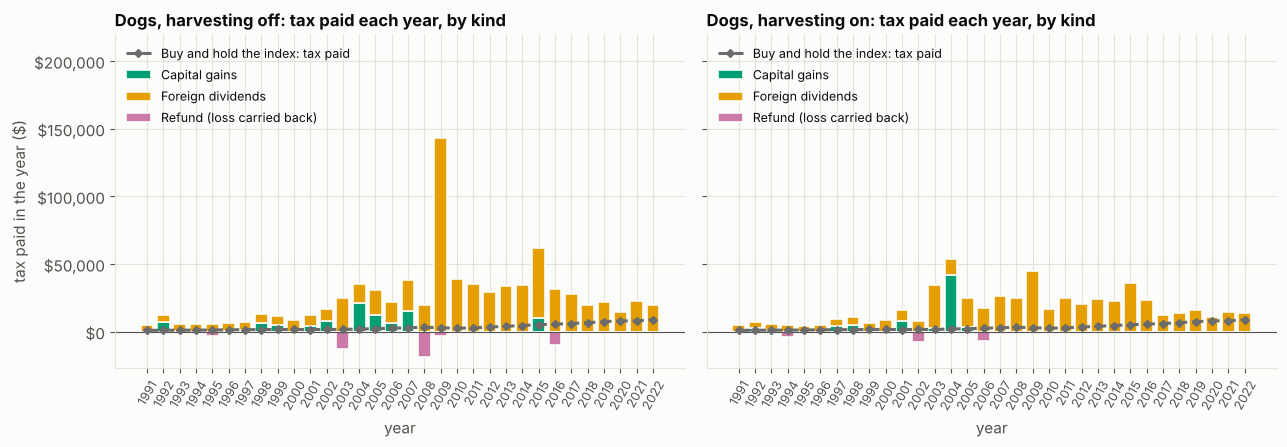

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, res, name in zip(axs, (off, on), ("Harvesting off", "Harvesting on")):
    tp.tax_paid_stack(res, ax=ax, baseline=idx, baseline_label="Buy and hold the index: tax paid",
                      title=f"Dogs, {name.lower()}: tax paid each year, by kind")
    ax.set_xlabel("year"); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
top = max(ax.get_ylim()[1] for ax in axs)
for ax in axs:
    ax.set_ylim(top=top * 1.45)
axs[1].set_ylabel("")
fig.tight_layout(); plt.show()

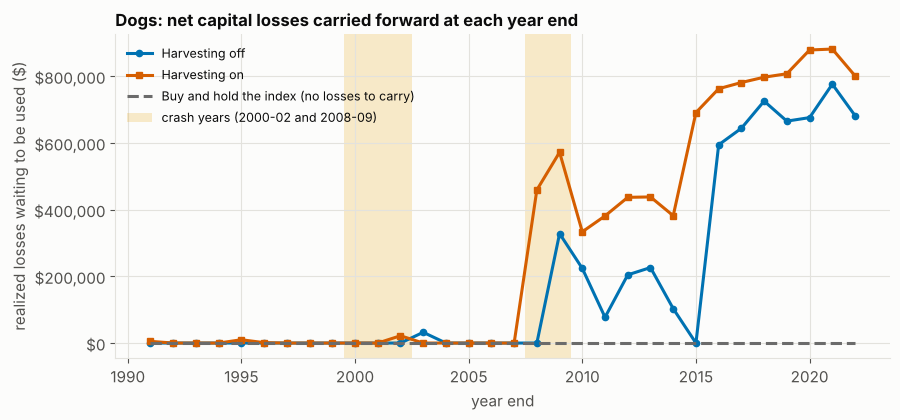

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for res, label, col, mk in ((off, "Harvesting off", OFF_COL, "o"), (on, "Harvesting on", ON_COL, "s")):
    s = res.tax["loss_carry_out"] * 1.0
    ax.plot(s.index, s.values, color=col, lw=2.2, marker=mk, ms=4.5, label=label)
s = idx.tax["loss_carry_out"] * 1.0
ax.plot(s.index, s.values, color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold the index (no losses to carry)", zorder=4)
for k, (y0, y1) in enumerate(CRASH.values()):
    ax.axvspan(y0 - 0.5, y1 + 0.5, color=ORANGE, alpha=0.20, lw=0, zorder=0, label="crash years (2000-02 and 2008-09)" if k == 0 else None)
ax.yaxis.set_major_formatter(lambda v, _: usd(v))
ax.set_ylabel("realized losses waiting to be used ($)"); ax.set_xlabel("year end")
ax.set_title("Dogs: net capital losses carried forward at each year end", loc="left", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", fontsize=9); plt.show()

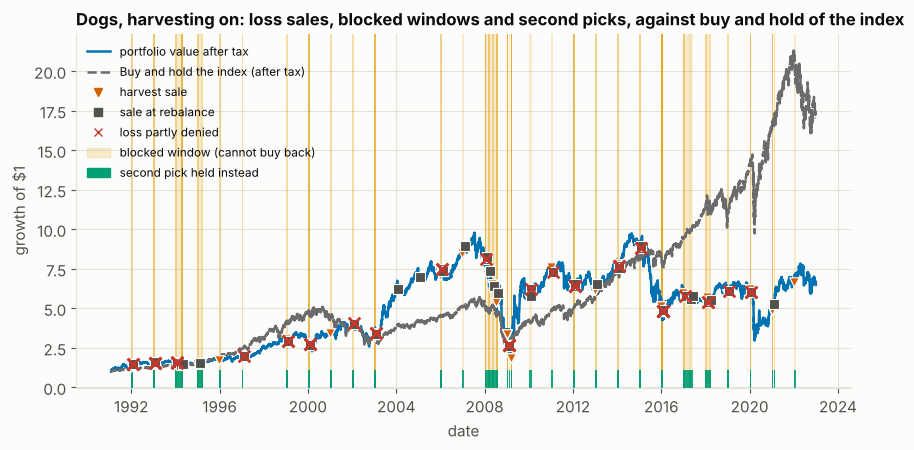

142 harvest sales, 44 sales with a denied loss, 142 with a second pick held for the window


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
tp.harvest_timeline(on, ax=ax, baseline=idx, after_tax=True,
                    title="Dogs, harvesting on: loss sales, blocked windows and second picks, against buy and hold of the index")
ax.set_xlabel("date"); plt.show()
print(f"{n_h} harvest sales, {n_denied} sales with a denied loss, {on.harvest['replacement_name'].notna().sum()} with a second pick held for the window")

In [13]:
md(f"""
**What the evidence says.** Harvesting on paid less tax than harvesting off in {n_less} of {n_years} years, by as much as {usd(tax_diff[y_best])} in {y_best}, and more in {n_more}, by as much as {usd(-tax_diff[y_worst])} in {y_worst}, and over the run {saved_txt(DG["saved"])}. The saving was therefore the net of swings in both directions between years. The stock of unused losses reached {usd(on.tax["loss_carry_out"].max())} in {int(on.tax["loss_carry_out"].idxmax())} with harvesting on, against {usd(off.tax["loss_carry_out"].max())} at its highest with harvesting off, and it stood at {usd(DG["carry_on"])} against {usd(DG["carry_off"])} at the end of 2022, so harvesting left {usd(DG["carry_on"] - DG["carry_off"])} more unused loss than the same screen without it, and both balances were large next to the gains still to come. Carry-back refunds, the bars below zero in the first chart, were {usd(refund_on)} in {len(refund_years_on)} years with harvesting on and {usd(refund_off)} in {len(refund_years_off)} years with it off. The index paid {usd(tax_idx)} over the whole run, all of it on dividends, because buy and hold realizes no gains and no losses. The timeline shows {n_h} harvest sales and {n_sales - n_h} sales at the screen's own rebalance, and {n_denied} sales in which the rule denied part of the loss.
""")


**What the evidence says.** Harvesting on paid less tax than harvesting off in 23 of 32 years, by as much as \$95,302 in 2009, and more in 8, by as much as \$24,176 in 2008, and over the run saved \$218,227. The saving was therefore the net of swings in both directions between years. The stock of unused losses reached \$881,648 in 2021 with harvesting on, against \$776,407 at its highest with harvesting off, and it stood at \$801,392 against \$682,053 at the end of 2022, so harvesting left \$119,340 more unused loss than the same screen without it, and both balances were large next to the gains still to come. Carry-back refunds, the bars below zero in the first chart, were \$21,999 in 7 years with harvesting on and \$50,142 in 7 years with it off. The index paid \$108,392 over the whole run, all of it on dividends, because buy and hold realizes no gains and no losses. The timeline shows 142 harvest sales and 106 sales at the screen's own rebalance, and 44 sales in which the rule denied part of the loss.


### 2.3 What harvesting cost

The third question is what the saving was bought with. The stage trades more, spends days away from the names the screen chose, and loses part of some losses to the superficial-loss rule. The table counts each cost for the two portfolios and for the base case, which never trades after the first purchase, and the chart shows the loss sold each year and the part the rule denied.

,Traded a year,Trading cost a year,Harvest sales,Sales at the screen's rebalance,Name-days out of the chosen names,Share of name-time out,Harvest sales not bought back,Sales with a denied loss,Loss sold,Loss denied
Buy and hold the index,0%,0.00%,0,0.000000,0,0.0%,0,0.000000,$0,$0
Harvesting off,76%,0.38%,0,-,0,0.0%,0,-,-,-
Harvesting on,137%,0.69%,142,106.000000,"4,142",3.6%,21,44.000000,"$2,695,670","$142,497"


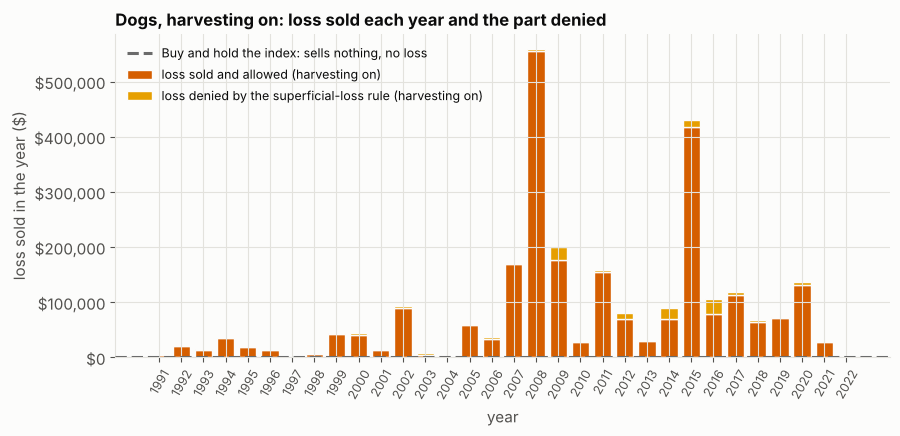

In [14]:
cost_tab = pd.DataFrame({
    "Traded a year": [0.0, DG["turn_off"], DG["turn_on"]], "Trading cost a year": [0.0, DG["cost_off"], DG["cost_on"]],
    "Harvest sales": [0, 0, DG["n_h"]], "Sales at the screen's rebalance": [0, np.nan, DG["n_screen"]],
    "Name-days out of the chosen names": [0, 0, DG["name_days"]], "Share of name-time out": [0.0, 0.0, DG["share_out"]],
    "Harvest sales not bought back": [0, 0, DG["n_h"] - DG["n_back"]],
    "Sales with a denied loss": [0, np.nan, DG["n_denied"]], "Loss sold": [0.0, np.nan, DG["loss_sold"]], "Loss denied": [0.0, np.nan, DG["loss_denied"]]},
    index=["Buy and hold the index", "Harvesting off", "Harvesting on"])
display(cost_tab.style.format({"Traded a year": "{:.0%}", "Trading cost a year": "{:.2%}", "Share of name-time out": "{:.1%}", "Name-days out of the chosen names": "{:,.0f}",
                               "Loss sold": usd, "Loss denied": usd}, na_rep="-"))
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(loss_by_year))
ax.bar(x, loss_by_year["allowed"], 0.78, color=ON_COL, edgecolor=SURFACE, label="loss sold and allowed (harvesting on)")
ax.bar(x, loss_by_year["denied"], 0.78, bottom=loss_by_year["allowed"], color=ORANGE, edgecolor=SURFACE, label="loss denied by the superficial-loss rule (harvesting on)")
ax.axhline(0, color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold the index: sells nothing, no loss", zorder=4)
ax.set_xticks(x, [str(y) for y in loss_by_year.index], rotation=60, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_ylabel("loss sold in the year ($)"); ax.set_xlabel("year")
ax.set_title("Dogs, harvesting on: loss sold each year and the part denied", loc="left", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", fontsize=9); plt.show()

In [15]:
md(f"""
**What the evidence says.** Harvesting raised turnover from {pc(turn_off, 0)} to {pc(turn_on, 0)} of the portfolio a year, {turn_on / turn_off:.1f} times as much, and trading cost from {pc(cost_off)} to {pc(cost_on)} a year. The account spent {DG["name_days"]:,} name-days out of the names the screen had chosen, {pc(DG["share_out"], 1)} of all its name-time, and {DG["n_h"] - DG["n_back"]} of the {DG["n_h"]} harvest sales were not bought back, because by the end of the window the screen no longer wanted the name (it had dropped out of the ranking, or the company was delisted or acquired), and those names are not counted in the name-days. The rule denied part of the loss on {n_denied} of {n_sales} loss sales, {usd(loss_denied)} of the {usd(loss_sold)} sold ({pc(loss_denied / loss_sold, 1)}). {DG["n_denied_h"]} of the denied sales were harvest sales: the blocklist kept the stage from buying a harvested name back inside its window, so every denial came from a sale at the screen's own rebalance, typically a second pick sold and then picked again within the 30 days. The cost was therefore mostly trading and time away from the names, and denial took a small share of the loss sold. The base case paid none of these costs, because it makes no trades.
""")


**What the evidence says.** Harvesting raised turnover from 76% to 137% of the portfolio a year, 1.8 times as much, and trading cost from 0.38% to 0.69% a year. The account spent 4,142 name-days out of the names the screen had chosen, 3.6% of all its name-time, and 21 of the 142 harvest sales were not bought back, because by the end of the window the screen no longer wanted the name (it had dropped out of the ranking, or the company was delisted or acquired), and those names are not counted in the name-days. The rule denied part of the loss on 44 of 248 loss sales, \$142,497 of the \$2,695,670 sold (5.3%). 0 of the denied sales were harvest sales: the blocklist kept the stage from buying a harvested name back inside its window, so every denial came from a sale at the screen's own rebalance, typically a second pick sold and then picked again within the 30 days. The cost was therefore mostly trading and time away from the names, and denial took a small share of the loss sold. The base case paid none of these costs, because it makes no trades.


## 3. How the gain depends on the settings

Section 2 used one setting, a 10% threshold at the year end, and found a result. This section asks whether that result belongs to the technique or to the one setting chosen. The stage leaves two choices open: how far a name must fall before it is sold (5%, 10% or 20%), and when it may be sold (only at the year end, only at the screen's own rebalance, or at both). The notebook ran all nine combinations on the same dogs screen, with daily bars as in section 2. The first chart shows each run's after-tax value against the two base cases, buy and hold of the index and harvesting off, and the second enlarges the differences from harvesting off, with the zoom of each timing in its own panel.

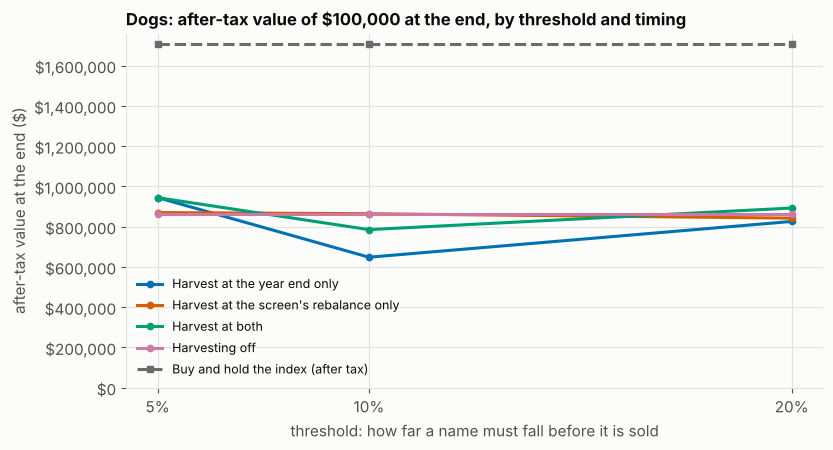

In [16]:
wide = sens.pivot(index="threshold", columns="when", values="final")[WHEN].reset_index()
wide["Harvesting off"] = at_off
wide[BH_INDEX] = at_idx
fig, ax = plt.subplots(figsize=(9, 4.6))
tp.sensitivity_lines(wide, "threshold", {"year_end": "Harvest at the year end only", "rebalance": "Harvest at the screen's rebalance only",
                                          "both": "Harvest at both", "Harvesting off": "Harvesting off", BH_INDEX: BH_INDEX},
                     ax=ax, baseline=(BH_INDEX,), xlabel="threshold: how far a name must fall before it is sold",
                     title="Dogs: after-tax value of $100,000 at the end, by threshold and timing")
ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_xticks(THR, [f"{t:.0%}" for t in THR])
ax.set_ylabel("after-tax value at the end ($)"); ax.set_ylim(bottom=0)
plt.show()

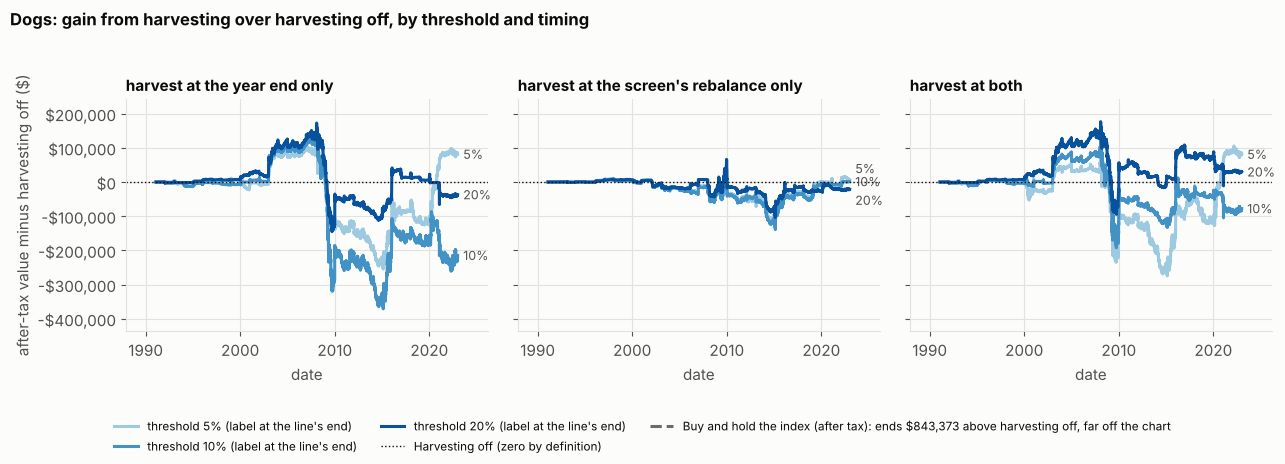

when,year_end,rebalance,both
Buy and hold the index (after tax),"$843,373","$843,373","$843,373"
Harvesting off,$0,$0,$0
Harvest when down 5%,"$81,365","$6,930","$81,107"
Harvest when down 10%,"-$214,878","$1,207","-$77,850"
Harvest when down 20%,"-$37,149","-$20,812","$29,461"


In [17]:
shades = {0.05: "#9ecae1", 0.10: "#4292c6", 0.20: "#08519c"}
lo, hi = min(c.min() for c in curves.values()), max(c.max() for c in curves.values())
pad = 0.12 * (hi - lo)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
titles = {"year_end": "harvest at the year end only", "rebalance": "harvest at the screen's rebalance only", "both": "harvest at both"}
for ax, when in zip(axs, WHEN):
    for th in THR:
        s = curves[when, th]
        ax.plot(s.index, s.values, color=shades[th], lw=2.2)
        ax.annotate(f"{th:.0%}", (s.index[-1], s.values[-1]), xytext=(4, {0.05: 8, 0.10: 0, 0.20: -8}[th] if when == "rebalance" else 0),
                    textcoords="offset points", fontsize=9, color=INK2, va="center")
    ax.axhline(0, color=INK, lw=1.0, ls=":")
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(titles[when], loc="left", fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.margins(x=0.1); ax.set_xlabel("date")
    ax.xaxis.set_major_locator(mdates.YearLocator(10)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axs[0].set_ylabel("after-tax value minus harvesting off ($)")
handles = [Line2D([], [], color=shades[t], lw=2.2, label=f"threshold {t:.0%} (label at the line's end)") for t in THR]
handles += [Line2D([], [], color=INK, lw=1.0, ls=":", label="Harvesting off (zero by definition)"),
            Line2D([], [], color=tp.INDEX_COL, ls="--", lw=2.2, label=BH_INDEX + f": ends {usd(idx_gain_vs_off)} above harvesting off, far off the chart")]
fig.suptitle("Dogs: gain from harvesting over harvesting off, by threshold and timing", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False)
fig.tight_layout(rect=(0, 0.13, 1, 0.95)); plt.show()
gain_tab = sens.pivot(index="threshold", columns="when", values="gain")[WHEN]
gain_tab.index = [f"Harvest when down {t:.0%}" for t in gain_tab.index]
gain_tab.loc["Harvesting off"] = 0.0
gain_tab.loc[BH_INDEX] = idx_gain_vs_off
display(gain_tab.loc[[BH_INDEX, "Harvesting off", *[i for i in gain_tab.index if i.startswith("Harvest when")]]]
        .style.format(usd).set_caption("After-tax value at the end minus harvesting off, $100,000 start"))

In [18]:
md(f"""
**What the evidence says.** The gain over harvesting off was positive in {n_pos} of the nine runs and negative in {n_neg}. It ranged from {usd(worst["gain"])} (threshold {worst["threshold"]:.0%}, sales {WHEN_NAME[worst["when"]]}) to {usd(best["gain"])} (threshold {best["threshold"]:.0%}, sales {WHEN_NAME[best["when"]]}), and the 10% year-end run of section 2, {usd(gain_at)}, sat {"above" if gain_at > sens["gain"].median() else "below"} the median of {usd(sens["gain"].median())}. A threshold of 5% made {int(hv_by_thr.loc[0.05, "min"])} to {int(hv_by_thr.loc[0.05, "max"])} harvest sales and a threshold of 20% made {int(hv_by_thr.loc[0.20, "min"])} to {int(hv_by_thr.loc[0.20, "max"])}, so the lower threshold harvested more often. More harvesting did not reliably gain more: in {n_nonmono} of the three timings the 10% threshold gave a result outside the range of the 5% and the 20% results, so the result did not move steadily with the threshold, which shows how much of each result was which names happened to be sold and which second picks happened to be held. The spread between the best and the worst run was {usd(best["gain"] - worst["gain"])}, which is {(best["gain"] - worst["gain"]) / abs(gain_at):.1f} times the size of the 10% year-end result, so the choice of setting mattered more than the technique. The most tax saved by any run was {usd(sens["tax_saved"].max())}, and the best harvesting run still ended {usd(at_idx - sens["final"].max())} below buy and hold of the index. The history is one draw of the market, so the direction and the order of magnitude carry the information, not the dollars.
""")


**What the evidence says.** The gain over harvesting off was positive in 5 of the nine runs and negative in 4. It ranged from -\$214,878 (threshold 10%, sales at the year end only) to \$81,365 (threshold 5%, sales at the year end only), and the 10% year-end run of section 2, -\$214,878, sat below the median of \$1,207. A threshold of 5% made 37 to 217 harvest sales and a threshold of 20% made 23 to 94, so the lower threshold harvested more often. More harvesting did not reliably gain more: in 2 of the three timings the 10% threshold gave a result outside the range of the 5% and the 20% results, so the result did not move steadily with the threshold, which shows how much of each result was which names happened to be sold and which second picks happened to be held. The spread between the best and the worst run was \$296,242, which is 1.4 times the size of the 10% year-end result, so the choice of setting mattered more than the technique. The most tax saved by any run was \$218,227, and the best harvesting run still ended \$762,009 below buy and hold of the index. The history is one draw of the market, so the direction and the order of magnitude carry the information, not the dollars.


## 4. The same test on two more screens

Section 3 varied the setting on one screen. This section asks whether the finding on dogs belongs to dogs. Dogs buys the most distressed, highest-yield names, which are the likeliest to be sold at a loss and the likeliest to be delisted, so it may be the screen most favourable to harvesting and the one most hurt by it. The other two screens are different kinds of portfolio: **momentum_12m** buys the ten best 12-month price gains of the whole S&P 500, and **stable_high_yield** buys the ten highest yields among the 50 least volatile payers. Both were run with the same account, the same 10% year-end rule and the same second pick, rebalanced yearly. The table has one row for each screen with harvesting off, the same screen with it on, and the base case.

,Pre-tax CAGR off,Pre-tax CAGR on,After-tax CAGR off,After-tax CAGR on,"Change, points",of which tax,of which before tax,Tax saved,Harvest sales,Denied sales,Traded a year off,Traded a year on
Screen,,,,,,,,,,,,
dogs,11.34%,9.69%,6.99%,6.04%,-0.96,+0.70,-1.66,"$218,227",142,44,76%,137%
momentum_12m,9.48%,7.87%,8.52%,7.16%,-1.36,+0.25,-1.61,"$93,105",125,32,93%,144%
stable_high_yield,9.79%,10.08%,7.45%,7.80%,+0.35,+0.07,+0.28,"-$23,029",51,15,50%,76%
Buy and hold the index,9.92%,9.92%,9.28%,9.28%,-,-,-,-,0,0,0%,0%


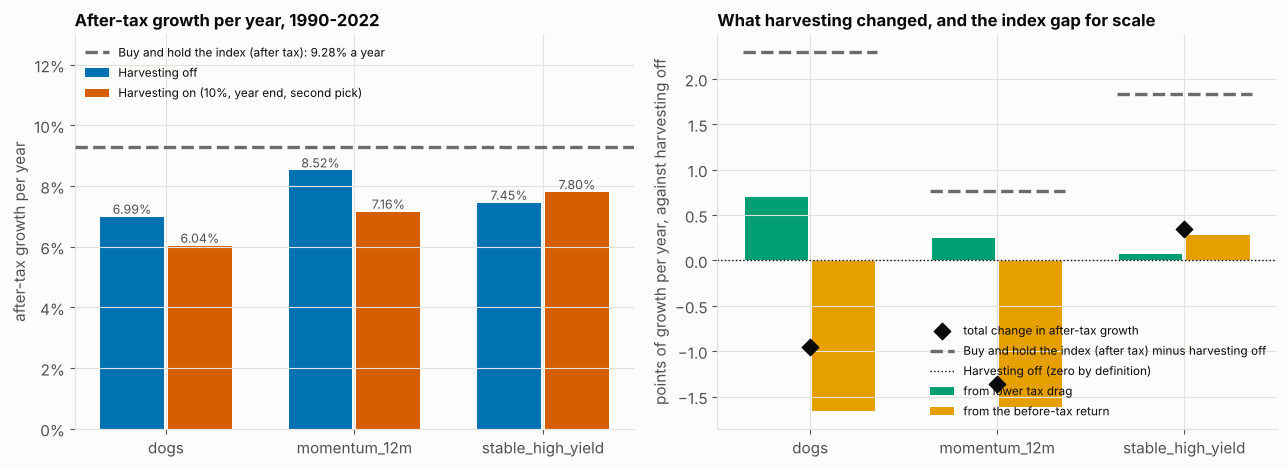

In [19]:
rows_s = []
for s_ in SCREENS:
    x = ST[s_]
    rows_s.append({"Screen": s_, "Pre-tax CAGR off": x["pre_off"], "Pre-tax CAGR on": x["pre_on"], "After-tax CAGR off": x["at_off"], "After-tax CAGR on": x["at_on"],
                   "Change, points": x["d_at"], "of which tax": x["d_drag"], "of which before tax": x["d_pre"], "Tax saved": x["saved"],
                   "Harvest sales": x["n_h"], "Denied sales": x["n_denied"], "Traded a year off": x["turn_off"], "Traded a year on": x["turn_on"]})
rows_s.append({"Screen": "Buy and hold the index", "Pre-tax CAGR off": idx_pre_cagr, "Pre-tax CAGR on": idx_pre_cagr, "After-tax CAGR off": idx_at_cagr,
               "After-tax CAGR on": idx_at_cagr, "Change, points": np.nan, "of which tax": np.nan, "of which before tax": np.nan, "Tax saved": np.nan,
               "Harvest sales": 0, "Denied sales": 0, "Traded a year off": 0.0, "Traded a year on": 0.0})
scr_tab = pd.DataFrame(rows_s).set_index("Screen")
display(scr_tab.style.format({"Pre-tax CAGR off": "{:.2%}", "Pre-tax CAGR on": "{:.2%}", "After-tax CAGR off": "{:.2%}", "After-tax CAGR on": "{:.2%}",
                              "Change, points": lambda v: pts(v), "of which tax": lambda v: pts(v), "of which before tax": lambda v: pts(v),
                              "Tax saved": usd, "Traded a year off": "{:.0%}", "Traded a year on": "{:.0%}"}, na_rep="-"))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(SCREENS)); w = 0.36
ax = axs[0]
b1 = ax.bar(x - w / 2, [ST[s_]["at_off"] for s_ in SCREENS], w * 0.94, color=OFF_COL, label="Harvesting off")
b2 = ax.bar(x + w / 2, [ST[s_]["at_on"] for s_ in SCREENS], w * 0.94, color=ON_COL, label="Harvesting on (10%, year end, second pick)")
ax.axhline(idx_at_cagr, color=tp.INDEX_COL, ls="--", lw=2.4, label=f"{BH_INDEX}: {pc(idx_at_cagr)} a year", zorder=4)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), pc(b.get_height()), ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(x, SCREENS); ax.yaxis.set_major_formatter(lambda v, _: f"{100 * v:g}%"); ax.set_ylim(0, 0.13)
ax.set_ylabel("after-tax growth per year"); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("After-tax growth per year, 1990-2022", loc="left", fontsize=12, fontweight="bold")
ax = axs[1]
ax.bar(x - w / 2, [100 * ST[s_]["d_drag"] for s_ in SCREENS], w * 0.94, color=GREEN, label="from lower tax drag")
ax.bar(x + w / 2, [100 * ST[s_]["d_pre"] for s_ in SCREENS], w * 0.94, color=ORANGE, label="from the before-tax return")
ax.scatter(x, [100 * ST[s_]["d_at"] for s_ in SCREENS], marker="D", s=70, color=INK, zorder=5, label="total change in after-tax growth")
for i, s_ in enumerate(SCREENS):
    ax.plot([i - w, i + w], [100 * (idx_at_cagr - ST[s_]["at_off"])] * 2, color=tp.INDEX_COL, ls="--", lw=2.4, zorder=4,
            label=f"{BH_INDEX} minus harvesting off" if i == 0 else None)
ax.axhline(0, color=INK, lw=1.0, ls=":", label="Harvesting off (zero by definition)")
ax.set_xticks(x, SCREENS); ax.set_ylabel("points of growth per year, against harvesting off"); ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("What harvesting changed, and the index gap for scale", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout(); plt.show()

In [20]:
md(f"""
**What the evidence says.** Harvesting raised after-tax growth on {n_up} of the three screens. The change in points a year was {pts(dg["d_at"])} on dogs, {pts(mo["d_at"])} on momentum_12m and {pts(sh["d_at"])} on stable_high_yield. The tax part was positive on {sum(ST[s_]["d_drag"] > 0 for s_ in SCREENS)} of the three, between {pts(min(ST[s_]["d_drag"] for s_ in SCREENS))} and {pts(max(ST[s_]["d_drag"] for s_ in SCREENS))} points, and the before-tax part was positive on {sum(ST[s_]["d_pre"] > 0 for s_ in SCREENS)}, between {pts(min(ST[s_]["d_pre"] for s_ in SCREENS))} and {pts(max(ST[s_]["d_pre"] for s_ in SCREENS))}. {"On every screen the before-tax part was larger in size than the tax part, so the result was set by the luck of the second picks and the sold names, and the tax saving was the smaller number." if all(abs(ST[s_]["d_pre"]) > abs(ST[s_]["d_drag"]) for s_ in SCREENS) else "The tax part was the larger number on at least one screen."} In dollars, harvesting {saved_txt(dg["saved"])} of tax on dogs, {saved_txt(mo["saved"])} on momentum_12m and {saved_txt(sh["saved"])} on stable_high_yield; on stable_high_yield a lower tax drag came with a higher before-tax return and so more dollars of gain to tax. Every screen traded more and paid more trading cost, and {n_beat} of the three harvesting portfolios beat the base case: buy and hold of the index grew {pc(idx_at_cagr)} a year after tax and the best harvesting portfolio {pc(max(ST[s_]["at_on"] for s_ in SCREENS))}. The sign of the result depended on the screen, so the finding on dogs cannot be carried to other screens without testing them.
""")


**What the evidence says.** Harvesting raised after-tax growth on 1 of the three screens. The change in points a year was -0.96 on dogs, -1.36 on momentum_12m and +0.35 on stable_high_yield. The tax part was positive on 3 of the three, between +0.07 and +0.70 points, and the before-tax part was positive on 1, between -1.66 and +0.28. On every screen the before-tax part was larger in size than the tax part, so the result was set by the luck of the second picks and the sold names, and the tax saving was the smaller number. In dollars, harvesting saved \$218,227 of tax on dogs, saved \$93,105 on momentum_12m and cost \$23,029 more on stable_high_yield; on stable_high_yield a lower tax drag came with a higher before-tax return and so more dollars of gain to tax. Every screen traded more and paid more trading cost, and 0 of the three harvesting portfolios beat the base case: buy and hold of the index grew 9.28% a year after tax and the best harvesting portfolio 7.80%. The sign of the result depended on the screen, so the finding on dogs cannot be carried to other screens without testing them.


## 5. Carry-back, and the two crashes inside the history

Sections 2 to 4 reported carry-back refunds in the tax tables without explaining them, and the question that decides whether harvesting pays is when a harvested loss is used. This section asks how a loss turns into a refund and when it cannot, first on two hand-built cases where the arithmetic is exact (5.1), and then on the two crashes in the real history, 2000-02 and 2008-09, when harvesting had the most losses to bank (5.2). Canada lets a net capital loss be applied to the taxable gains of the **three previous years**, most recent first, and the tax paid on them is refunded. Whatever remains carries forward and offsets only future gains.

### 5.1 How a loss becomes a refund (a hand-built illustration)

Two cases use a flat 20% rate. In the first, gains were taxed in three years and a loss followed in the fourth. In the second, the loss was large enough to run out of years. These cases are bare tax events with no price path, so they have no index to hold. The base case in the charts is the never-sell holder, who realizes no loss and receives no refund, drawn as the grey dashed zero line.

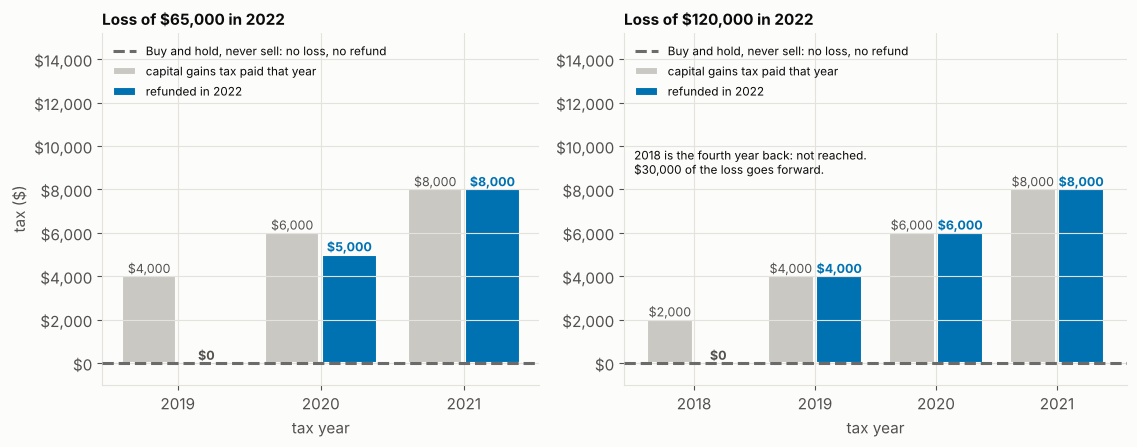

,"case 1 ($65,000 loss)","case 2 ($120,000 loss)","buy and hold, never sell"
realized_losses,"-$65,000","-$120,000",$0
carried_back,"$65,000","$90,000",$0
refund,"$13,000","$18,000",$0
loss_carry_out,$0,"$30,000",$0


carry-back refund: case 1 $13,000, case 2 $18,000; carried forward in case 2: $30,000


In [21]:
def carry_chart(t, ax, title, years, loss_year=2022):
    by = t.attrs["year_tax"][loss_year].breakdown["refund_by_year"]
    x = np.arange(len(years)); paid = [t.loc[y, "tax_capital_gains"] for y in years]; back = [by.get(y, 0.0) for y in years]
    ax.axhline(0, color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold, never sell: no loss, no refund", zorder=4)
    ax.bar(x - 0.2, paid, 0.38, color="#c9c8c2", label="capital gains tax paid that year", edgecolor=SURFACE, lw=1.5)
    ax.bar(x + 0.2, back, 0.38, color=BLUE, label=f"refunded in {loss_year}", edgecolor=SURFACE, lw=1.5)
    for xi, p, b in zip(x, paid, back):
        ax.text(xi - 0.2, p + 150, usd(p), ha="center", fontsize=9, color=INK2)
        ax.text(xi + 0.2, b + 150, usd(b), ha="center", fontsize=9, color=BLUE if b else INK2, fontweight="bold")
    ax.set_xticks(x, [str(y) for y in years]); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
    ax.set_ylim(-1_000, max(paid) * 1.9)
    ax.set_xlabel("tax year"); ax.set_title(title, loc="left", fontsize=11, fontweight="bold"); ax.legend(loc="upper left", fontsize=8.5)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
carry_chart(case1, axs[0], "Loss of $65,000 in 2022", [2019, 2020, 2021])
carry_chart(case2, axs[1], "Loss of $120,000 in 2022", [2018, 2019, 2020, 2021])
axs[1].text(0.02, 0.60, "2018 is the fourth year back: not reached.\n$30,000 of the loss goes forward.", transform=axs[1].transAxes, ha="left", fontsize=8.5, color=INK)
axs[0].set_ylabel("tax ($)")
fig.tight_layout(); plt.show()
show = pd.DataFrame({"case 1 ($65,000 loss)": case1.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]],
                     "case 2 ($120,000 loss)": case2.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]]})
show["buy and hold, never sell"] = 0.0
display(show.style.format(usd))
print(f"carry-back refund: case 1 {usd(case1.loc[2022, 'refund'])}, case 2 {usd(case2.loc[2022, 'refund'])};"
      f" carried forward in case 2: {usd(case2.loc[2022, 'loss_carry_out'])}")

In [22]:
md(f"""
The loss year's `tax_paid` becomes a credit (a negative number), which is the refund received on filing for the loss year. A real return asks for it with form T1A, and the model assumes it was filed. A forward balance is not carried back later.

**What the evidence says.** The refund was the 20% rate times the part of the loss that found tax already paid. In case 1 the {usd(-case1.loc[2022, "realized_losses"])} loss was applied to 2021 and then 2020 and refunded {usd(case1.loc[2022, "refund"])}. In case 2 only the three years 2019 to 2021 were reached, so {usd(case2.loc[2022, "carried_back"])} of the {usd(-case2.loc[2022, "realized_losses"])} loss was refunded {usd(case2.loc[2022, "refund"])} and {usd(case2.loc[2022, "loss_carry_out"])} went forward to wait for future gains. A refund therefore needs tax that was paid in the three previous years. A year with no tax paid, and a loss that is the first in a long run of losses, has nothing to refund. Section 5.2 shows how often that happened in the real history.
""")


The loss year's `tax_paid` becomes a credit (a negative number), which is the refund received on filing for the loss year. A real return asks for it with form T1A, and the model assumes it was filed. A forward balance is not carried back later.

**What the evidence says.** The refund was the 20% rate times the part of the loss that found tax already paid. In case 1 the \$65,000 loss was applied to 2021 and then 2020 and refunded \$13,000. In case 2 only the three years 2019 to 2021 were reached, so \$90,000 of the \$120,000 loss was refunded \$18,000 and \$30,000 went forward to wait for future gains. A refund therefore needs tax that was paid in the three previous years. A year with no tax paid, and a loss that is the first in a long run of losses, has nothing to refund. Section 5.2 shows how often that happened in the real history.


### 5.2 The crash years, 2000-02 and 2008-09

The second question is what the harvested losses did in the two crashes. Crashes produce the largest losses, so they are where harvesting should earn its keep, and the carry-back is how a loss is used while prices are still low. The chart shows, for dogs and for the years around each crash, the losses realized with harvesting off and on, the carry-back refunds, and the stock of unused losses at each year end. The base case is buy and hold of the index, which realizes no loss and gets no refund. The table adds the harvest stage's own sales, the gains the losses were set against, the tax paid, and the balance still waiting five years after the window.

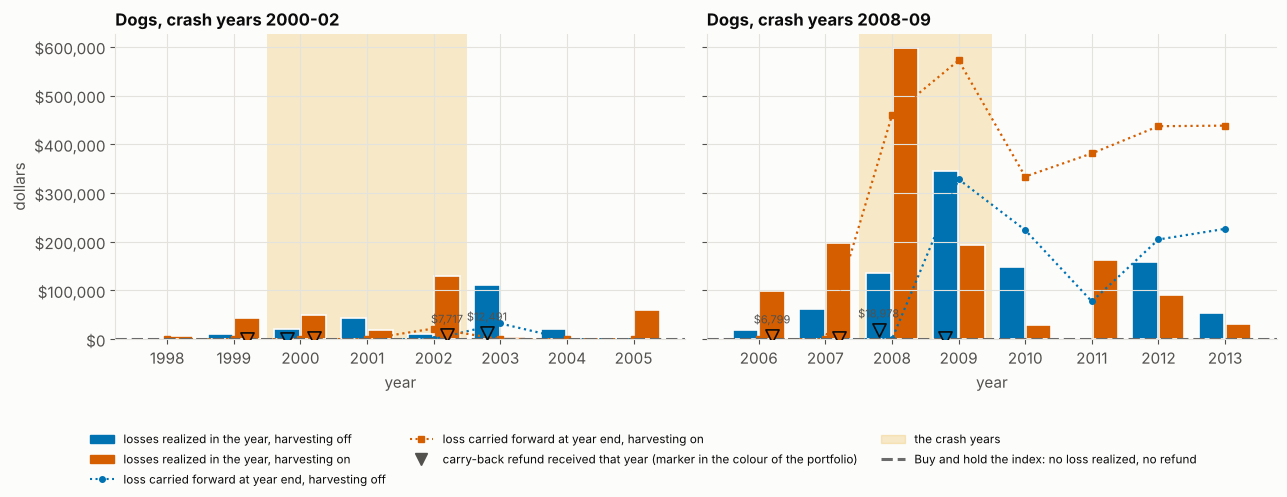

,Losses realized,Sold by the harvest stage,Gains realized,Tax paid,Carry-back refund,Carried forward at the end of the window,Carried forward five years later
2000-02 harvesting off,"$75,648",-,"$137,993","$36,443","$1,229",$0,$0
2000-02 harvesting on,"$198,297","$138,140","$168,530","$23,341","$9,077","$21,857",$0
2000-02 buy and hold the index,$0,$0,$0,"$4,999",$0,$0,$0
2008-09 harvesting off,"$481,270",-,"$39,918","$141,212","$21,992","$328,178","$103,195"
2008-09 harvesting on,"$789,924","$590,514","$217,871","$70,086",$0,"$572,053","$381,932"
2008-09 buy and hold the index,$0,$0,$0,"$6,243",$0,$0,$0


2000-02: carry-back with harvesting on refunded tax paid in [1998, 2001]; balance five years later is the value at the end of 2007
2008-09: carry-back with harvesting on refunded tax paid in no earlier year; balance five years later is the value at the end of 2014


In [23]:
PAD = {"2000-02": (1998, 2005), "2008-09": (2006, 2013)}
fig, axs = plt.subplots(1, 2, figsize=(13, 5.0), sharey=True)
for ax, (name, (y0, y1)) in zip(axs, CRASH.items()):
    ys = list(range(PAD[name][0], PAD[name][1] + 1)); x = np.arange(len(ys))
    ax.axvspan(ys.index(y0) - 0.5, ys.index(y1) + 0.5, color=ORANGE, alpha=0.20, lw=0, zorder=0)
    ax.bar(x - 0.2, -off.tax.loc[ys, "realized_losses"], 0.38, color=OFF_COL, edgecolor=SURFACE, lw=1.2)
    ax.bar(x + 0.2, -on.tax.loc[ys, "realized_losses"], 0.38, color=ON_COL, edgecolor=SURFACE, lw=1.2)
    ax.plot(x, off.tax.loc[ys, "loss_carry_out"], color=OFF_COL, lw=1.6, ls=":", marker="o", ms=4)
    ax.plot(x, on.tax.loc[ys, "loss_carry_out"], color=ON_COL, lw=1.6, ls=":", marker="s", ms=4)
    for dx, res, col in ((-0.2, off, OFF_COL), (0.2, on, ON_COL)):
        for xi, v in zip(x, res.tax.loc[ys, "refund"]):
            if v > 0:
                ax.scatter([xi + dx], [v], marker="v", s=90, facecolor=col, edgecolor=INK, linewidths=1.2, zorder=6)
                if v >= 5_000:
                    ax.annotate(usd(v), (xi + dx, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.axhline(0, color=tp.INDEX_COL, ls="--", lw=2.2, zorder=4)
    ax.set_xticks(x, [str(y) for y in ys]); ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_xlabel("year")
    ax.set_title(f"Dogs, crash years {name}", loc="left", fontsize=12, fontweight="bold")
axs[0].set_ylabel("dollars")
handles = [Patch(color=OFF_COL, label="losses realized in the year, harvesting off"), Patch(color=ON_COL, label="losses realized in the year, harvesting on"),
           Line2D([], [], color=OFF_COL, ls=":", marker="o", ms=4, label="loss carried forward at year end, harvesting off"),
           Line2D([], [], color=ON_COL, ls=":", marker="s", ms=4, label="loss carried forward at year end, harvesting on"),
           Line2D([], [], marker="v", color=INK2, lw=0, ms=9, label="carry-back refund received that year (marker in the colour of the portfolio)"),
           Patch(color=ORANGE, alpha=0.20, label="the crash years"),
           Line2D([], [], color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold the index: no loss realized, no refund")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False)
fig.tight_layout(rect=(0, 0.17, 1, 1)); plt.show()
rows_c = {}
for name, v in CR.items():
    rows_c[f"{name} harvesting off"] = {"Losses realized": v["real_off"], "Sold by the harvest stage": np.nan, "Gains realized": v["gains_off"], "Tax paid": v["tax_off"],
                                        "Carry-back refund": v["refund_off"], "Carried forward at the end of the window": v["carry_off"],
                                        f"Carried forward five years later": v["carry5_off"]}
    rows_c[f"{name} harvesting on"] = {"Losses realized": v["real_on"], "Sold by the harvest stage": v["harvest_loss"], "Gains realized": v["gains_on"], "Tax paid": v["tax_on"],
                                       "Carry-back refund": v["refund_on"], "Carried forward at the end of the window": v["carry_on"],
                                       f"Carried forward five years later": v["carry5_on"]}
    rows_c[f"{name} buy and hold the index"] = {"Losses realized": 0.0, "Sold by the harvest stage": 0.0, "Gains realized": 0.0, "Tax paid": v["tax_idx"],
                                                "Carry-back refund": 0.0, "Carried forward at the end of the window": 0.0, f"Carried forward five years later": 0.0}
display(pd.DataFrame(rows_c).T.style.format(usd, na_rep="-"))
for name, v in CR.items():
    print(f"{name}: carry-back with harvesting on refunded tax paid in {v['back_years'] or 'no earlier year'}; balance five years later is the value at the end of {v['after5']}")

In [24]:
c1, c2 = CR["2000-02"], CR["2008-09"]
md(f"""
**What the evidence says.** In 2000-02 harvesting on realized {usd(c1["real_on"])} of losses against {usd(c1["real_off"])} with harvesting off, of which the harvest stage sold {usd(c1["harvest_loss"])}, and the carry-back refunded {usd(c1["refund_on"])} (tax paid in {" and ".join(map(str, c1["back_years"]))}) against {usd(c1["refund_off"])}. The account paid {usd(c1["tax_on"])} of tax in those three years against {usd(c1["tax_off"])} without harvesting, and {usd(c1["tax_idx"])} for buy and hold of the index. Gains realized in those years, {usd(c1["gains_on"])}, were met by losses, and the part that found earlier tax came back, so the crash was a case where harvesting did what it is meant to do. In 2008-09 harvesting on realized {usd(c2["real_on"])} of losses against {usd(c2["real_off"])}, of which {usd(c2["harvest_loss"])} was sold by the harvest stage, and paid {usd(c2["tax_on"])} of tax against {usd(c2["tax_off"])} without harvesting. The carry-back refunded {usd(c2["refund_on"])} with harvesting on and {usd(c2["refund_off"])} with it off, because the tax paid in 2005-07 had already been refunded in part by the smaller net losses of 2006 and 2007 ({usd(on.tax.loc[[2006, 2007], "refund"].sum())} in all), so there was almost no tax left to refund. The loss went forward instead: {usd(c2["carry_on"])} at the end of 2009 and still {usd(c2["carry5_on"])} at the end of {c2["after5"]}, against {usd(c2["carry5_off"])} with harvesting off, and {usd(DG["carry_on"])} at the end of 2022. The balance fell only slowly even though the account realized {usd(c2["gains_after"])} of gains in the five years after the crash, because it realized {usd(c2["losses_after"])} of new losses in the same years. Most of the value of a harvested crash loss was therefore a tax asset that waited, and not a refund received.
""")


**What the evidence says.** In 2000-02 harvesting on realized \$198,297 of losses against \$75,648 with harvesting off, of which the harvest stage sold \$138,140, and the carry-back refunded \$9,077 (tax paid in 1998 and 2001) against \$1,229. The account paid \$23,341 of tax in those three years against \$36,443 without harvesting, and \$4,999 for buy and hold of the index. Gains realized in those years, \$168,530, were met by losses, and the part that found earlier tax came back, so the crash was a case where harvesting did what it is meant to do. In 2008-09 harvesting on realized \$789,924 of losses against \$481,270, of which \$590,514 was sold by the harvest stage, and paid \$70,086 of tax against \$141,212 without harvesting. The carry-back refunded \$0 with harvesting on and \$21,992 with it off, because the tax paid in 2005-07 had already been refunded in part by the smaller net losses of 2006 and 2007 (\$8,761 in all), so there was almost no tax left to refund. The loss went forward instead: \$572,053 at the end of 2009 and still \$381,932 at the end of 2014, against \$103,195 with harvesting off, and \$801,392 at the end of 2022. The balance fell only slowly even though the account realized \$573,767 of gains in the five years after the crash, because it realized \$383,645 of new losses in the same years. Most of the value of a harvested crash loss was therefore a tax asset that waited, and not a refund received.


## 6. Exits: the sale that a risk signal makes (a hand-built illustration)

Sections 1 to 5 treated the sale as a choice made for tax. This section asks what happens when a risk signal forces the sale. It follows from the others because the rule does not care why the account sold: an exit policy parks the portfolio in cash while a risk flag is on, which sells everything, including a name sitting on a loss. That sale is a loss like any other, so the stage records it (`source` "exit") and blocks the name.

The flag went on at **S = 1 September 2020**, when A was down 20% from its purchase price of 1.0. A was back to 1.0 on 20 September and to 1.1 on 5 October. Three ways the flag could clear were run. In the first, the flag cleared at S + 10 days and the second pick took the money: A was blocked until S + 30, B was held, and A came back at S + 31. In the second, the flag cleared at S + 31 days, just after the window, and A was bought straight back. In the third, the flag cleared at S + 10 days and the rule was set to allow denial, so A was bought back at once and the loss was denied.

The base case is the same account that holds A and never sells, which means no exit signal and no harvesting. It is the right comparison because it shows what the exit and the window cost in forgone gains, which the table of losses alone cannot show.

In [25]:
display(t4)

,sale recorded as,loss,bought instead,A held again on,denied,loss realized in 2020,wealth on 6 Oct
variant,,,,,,,
"Buy and hold A (no exit, never sell)",-,$0,-,-,$0,$0,"$110,000"
"Back in at S+10, second pick",exit,"$20,000",B,2020-10-02,$0,"$20,000","$88,000"
"Back in at S+31, second pick",exit,"$20,000",A (the same name),2020-10-02,$0,"$20,000","$88,000"
"Back in at S+10, allow denial",exit,"$20,000",A (the same name),2020-09-11,"$20,000",$0,"$110,000"


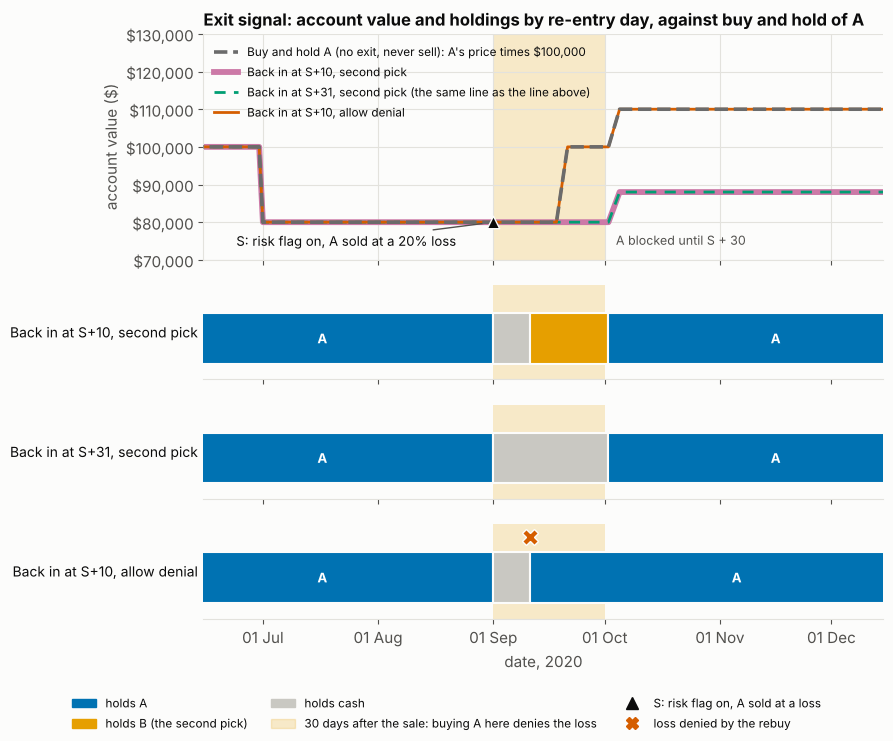

In [26]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 7.4), gridspec_kw=dict(height_ratios=[2.4, 1, 1, 1], hspace=0.2))
win = (S, S + pd.Timedelta(days=30)); ax = axs[0]
ax.plot(a_exit.index, a_exit.values * CAP, color=tp.INDEX_COL, ls="--", lw=2.6, label=BH_A4 + ": A\'s price times $100,000", zorder=5)
for k, r in res4.items():
    ax.plot(r.curve.index, r.curve.values * CAP, color=EXIT_COL[k], lw=4.2 if k.startswith("Back in at S+10, second") else 2.0,
            ls=(0, (4, 3)) if k.startswith("Back in at S+31") else "-", label=k + (" (the same line as the line above)" if k.startswith("Back in at S+31") else ""))
ax.scatter([S], [a_exit.loc[S] * CAP], marker="^", s=80, color=INK, zorder=6, edgecolor=SURFACE)
ax.annotate("S: risk flag on, A sold at a 20% loss", (S, a_exit.loc[S] * CAP), xytext=(-185, -17), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.text(S + pd.Timedelta(days=33), 74_000, "A blocked until S + 30", fontsize=9, color=INK2)
ax.set_ylabel("account value ($)"); ax.set_ylim(70_000, 130_000); ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Exit signal: account value and holdings by re-entry day, against buy and hold of A", loc="left", fontsize=12, fontweight="bold")
for ax_, (name, (b, _)), r in zip(axs[1:], EXITS.items(), res4.values()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A", end=pd.Timestamp("2020-12-31"), reentry=b, start=pd.Timestamp("2020-06-01")), name, window=win,
              denied_at=b if h["denied"] > 0 else None)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axs[-1].set_xlim(pd.Timestamp("2020-06-15"), pd.Timestamp("2020-12-15")); axs[-1].set_xlabel("date, 2020")
strip_legend(fig, "S: risk flag on, A sold at a loss", "^", INK)
fig.subplots_adjust(left=0.22, bottom=0.16, top=0.95)
plt.show()

In [27]:
rows4_loss = res4["Back in at S+10, second pick"].harvest.iloc[0]["loss"] * CAP
rows4_denied = res4["Back in at S+10, allow denial"].harvest.iloc[0]["denied"] * CAP

In [28]:
md(f"""
**What the evidence says.** An exit sale was treated as a harvest sale, and in this made-up path the window was expensive. The exit realized a {usd(rows4_loss)} loss in all three variants, but with the second pick the account bought A back on 2 October at 1.0 after A had already risen from 0.8, so on 6 October it was worth {usd(w4['Back in at S+10, second pick'])} against {usd(bh4)} for buy and hold of A. The {usd(bh4 - w4['Back in at S+10, second pick'])} difference was the rebound the account missed, set against a tax value of {usd(rows4_loss * FLAT_RATE)} at 20%. Clearing the flag at S + 31 changed nothing, because both second-pick variants bought A back on the same day. Allow denial recovered the rebound, with {usd(w4['Back in at S+10, allow denial'])} on 6 October, the same as buy and hold, but forfeited the loss: {usd(rows4_denied)} was denied. On this path the rule cost more than the loss was worth. The path was built to show the mechanics, and on a path where A kept falling the comparison would reverse.
""")


**What the evidence says.** An exit sale was treated as a harvest sale, and in this made-up path the window was expensive. The exit realized a \$20,000 loss in all three variants, but with the second pick the account bought A back on 2 October at 1.0 after A had already risen from 0.8, so on 6 October it was worth \$88,000 against \$110,000 for buy and hold of A. The \$22,000 difference was the rebound the account missed, set against a tax value of \$4,000 at 20%. Clearing the flag at S + 31 changed nothing, because both second-pick variants bought A back on the same day. Allow denial recovered the rebound, with \$110,000 on 6 October, the same as buy and hold, but forfeited the loss: \$20,000 was denied. On this path the rule cost more than the loss was worth. The path was built to show the mechanics, and on a path where A kept falling the comparison would reverse.


## 7. Reading guide: what is real, what is approximate, what the model leaves out

The sections above used a detailed model on real data, so this section asks how far their numbers can be trusted and which omissions matter. It follows from sections 2 to 5 because each of their findings rests on the items below.

**What is real.** Daily prices and cash dividends per share for every company in the S&P 500 on each date from 1990 to 2022, with the index membership as it stood then, so a company that fell out of the index or was delisted is in the data until it goes (the data card above reports a survivorship effect near zero). The benchmark, SP500_TR, is the real S&P 500 total return. Real crashes, real delistings and real dividend cuts are what the screens bought.

**What is approximate.**

* **Delisted companies.** A company whose prices end takes a flat 30% delisting haircut, whether it went bankrupt or was bought at a premium. This is harsh for takeovers and generous for failures, and the choice can matter most for a screen that buys distressed names, such as dogs.
* **Tax tables.** The 2025 Alberta and federal tables are applied to every year from 1990 to 2022, with a capital gains inclusion rate and dividend credits as they are today. Real rates, brackets and inclusion rates were different in each year.
* **Currency.** The prices are US dollars with no exchange-rate series, so gains are taxed in US dollars, not in Canadian dollars at the exchange rates of the buy and sell days. The dividends are treated as foreign income with 15% withholding credited.
* **Screens.** The panel has no market cap or fundamentals, so dogs is the ten highest yields of the whole S&P 500 and not the Globe's 30 largest, and stable_high_yield ranks the 50 least volatile payers of the whole index. The numbers are those of these screens, not of the published ones.
* **Data quality.** The panel mixes CRSP, Yahoo, Tiingo and Quandl WIKI sources with small unreconciled differences, and the cleaning drops dividend outliers (see the data card).
* **One history.** 33 years is one draw. The 2008-09 crash is a large share of what dogs did, and a different crash would give a different answer. No confidence interval is attached to any number here.
* **Trading costs.** 25 basis points per one-way trade and no bid-ask spread beyond it.
* **Harvest records.** `Result.harvest` states `loss` and `denied` on the pre-tax wealth scale, while the tax ledger is in the account's own dollars after tax was paid out of it (the ratio falls to about 0.35 by 2021). The notebook multiplies each record by after-tax over pre-tax wealth on its sale date, so that dollars of loss sold agree with the ledger.
* **`days_out`.** The library's days-out count for a harvested name that is never bought back runs to the end of the data (up to about 11,000 days). The notebook counts days only for names that were bought back.

**What the model leaves out.**

* **Spouse and affiliated accounts.** CRA also denies the loss if your spouse, your RRSP or TFSA, or a corporation you control buys the same name in the window. The model sees one taxable account only.
* **Identical property.** Swapping one ETF for another that tracks the same index may or may not count as identical for CRA. The model knows only names, and a second pick is a different company.
* **Settlement dates.** The model uses trade dates, and the real rule uses settlement dates, which fall two business days later in the market of the day.
* **"Still held at the end of the window".** The rule bites only if the rebought shares are still held at the end of the 30 days. The model treats any repurchase in the window as denying the loss, which is the cautious reading and slightly overstates the denial.
* **TFSA and RRSP.** A loss inside a registered account is worthless, so harvesting there is pointless. In a registered account **ignore the TaxDeferred/yr column**, which is computed anyway although nothing is deferred.
* **Tax law.** The flat 20% in sections 1, 5.1 and 6 gives clean arithmetic, and sections 2 to 5.2 use the library's Alberta model with brackets. Neither is tax advice.

In [29]:
md(f"""
**What the evidence says.** The omissions of the second kind, the superficial-loss details, can only deny losses that the model allowed, so they would make the real saving smaller than the measured one, and the measured saving was already small beside the swings of the before-tax return. The 2025 tables and the missing currency series can move the dollars of tax, and the base case and both harvesting settings face the same tables. The approximate delisting haircut can matter most to a screen that buys distressed names, such as dogs; run `lab.backtest(..., delist_return=0)` for the bound. The notebook therefore supports a narrow conclusion. On 33 years of real S&P 500 data, with a second pick and no rebuy inside the window, the 10% year-end rule saved tax on the screens with large losses ({usd(dg["saved"])} on dogs and {usd(mo["saved"])} on momentum_12m) and cost {pc(dg["cost_on"] - dg["cost_off"])} a year of extra trading cost on dogs and weeks of time away from the chosen names, but after tax it lowered growth on {3 - n_up} of the three screens, and the tax saved was small beside the choice of what to hold. Harvesting is a tool for the tax bill, and it did not make a screen beat the index.

**Where to look next.** `docs/TAXES.md`, "Loss harvesting"; `tests/test_harvesting.py` (the hand-built markets above, with every number asserted); `docs/GETTING_STARTED.md`, "Point-in-time S&P 500 panel (local use only)", for the data and its licence; `notebooks/accounts_and_foreign.ipynb` for which account a portfolio should live in; `notebooks/tax_where_to_hold.ipynb` for the same buy-and-hold index comparison across accounts. In a TFSA or RRSP ignore the TaxDeferred/yr column.
""")


**What the evidence says.** The omissions of the second kind, the superficial-loss details, can only deny losses that the model allowed, so they would make the real saving smaller than the measured one, and the measured saving was already small beside the swings of the before-tax return. The 2025 tables and the missing currency series can move the dollars of tax, and the base case and both harvesting settings face the same tables. The approximate delisting haircut can matter most to a screen that buys distressed names, such as dogs; run `lab.backtest(..., delist_return=0)` for the bound. The notebook therefore supports a narrow conclusion. On 33 years of real S&P 500 data, with a second pick and no rebuy inside the window, the 10% year-end rule saved tax on the screens with large losses (\$218,227 on dogs and \$93,105 on momentum_12m) and cost 0.31% a year of extra trading cost on dogs and weeks of time away from the chosen names, but after tax it lowered growth on 2 of the three screens, and the tax saved was small beside the choice of what to hold. Harvesting is a tool for the tax bill, and it did not make a screen beat the index.

**Where to look next.** `docs/TAXES.md`, "Loss harvesting"; `tests/test_harvesting.py` (the hand-built markets above, with every number asserted); `docs/GETTING_STARTED.md`, "Point-in-time S&P 500 panel (local use only)", for the data and its licence; `notebooks/accounts_and_foreign.ipynb` for which account a portfolio should live in; `notebooks/tax_where_to_hold.ipynb` for the same buy-and-hold index comparison across accounts. In a TFSA or RRSP ignore the TaxDeferred/yr column.
